<a href="https://colab.research.google.com/github/dewaputufajar308/Tugas4-Geospatial-Visualization/blob/main/Tugas4_Geo_203012510036_Dewa_Putu_Fajar_Wijayakusuma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Persiapan data

In [115]:
# ==========================================
# TUGAS 4 - GEOSPATIAL VISUALIZATION
# PERSIAPAN DATA
# ==========================================

import os
import zipfile
import pandas as pd
from pathlib import Path

# Clone repository GitHub
REPO_URL = "https://github.com/dewaputufajar308/Tugas4-Geospatial-Visualization.git"
REPO_DIR = Path("/content/Tugas4-Geospatial-Visualization")

if not REPO_DIR.exists():
    os.system(f"git clone {REPO_URL} {REPO_DIR}")

# Cari dataset ZIP
zip_path = REPO_DIR / "2030125100036_aduan_sukaraya.zip"

# Sesuaikan jika nama file berbeda
if not zip_path.exists():
    zip_files = list(REPO_DIR.glob("*.zip"))
    if not zip_files:
        raise FileNotFoundError("Dataset ZIP tidak ditemukan di repository.")
    zip_path = zip_files[0]

# Ekstrak dataset
DATA_DIR = REPO_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(DATA_DIR)

# Cari dan baca file CSV
csv_files = list(DATA_DIR.rglob("*.csv"))

print("FILE DATASET YANG DITEMUKAN:")
for file in csv_files:
    print("-", file.name)

# Identifikasi dataset berdasarkan nama file
aduan_path = next(f for f in csv_files if "aduan" in f.name.lower())
wilayah_path = next(f for f in csv_files if "wilayah" in f.name.lower())
penugasan_path = next(f for f in csv_files if "penugasan" in f.name.lower())

aduan_df = pd.read_csv(aduan_path)
wilayah_df = pd.read_csv(wilayah_path)
penugasan_df = pd.read_csv(penugasan_path)

print("\nRINGKASAN DATASET")
for nama, df in [
    ("Aduan", aduan_df),
    ("Wilayah", wilayah_df),
    ("Penugasan", penugasan_df)
]:
    print(f"\n{nama}: {df.shape[0]} baris, {df.shape[1]} kolom")
    print("Kolom:", df.columns.tolist())

FILE DATASET YANG DITEMUKAN:
- 203012510036_penugasan.csv
- wilayah_kota_sukaraya.csv
- 203012510036_aduan.csv

RINGKASAN DATASET

Aduan: 5049 baris, 9 kolom
Kolom: ['id_aduan', 'tanggal', 'kanal', 'kelurahan', 'kategori_dilaporkan', 'isi_aduan', 'lon', 'lat', 'status']

Wilayah: 12 baris, 6 kolom
Kolom: ['kelurahan', 'kecamatan', 'jumlah_penduduk', 'luas_km2', 'lon_pusat', 'lat_pusat']

Penugasan: 11626 baris, 6 kolom
Kolom: ['id_aduan', 'urutan', 'dinas', 'tanggal_terima', 'tanggal_selesai', 'catatan']


## Audit

### Audit kualitas dan kelengkapan data

In [116]:
# ==========================================
# BAGIAN A - AUDIT KUALITAS DATA
# ==========================================

datasets = {
    "Aduan": aduan_df,
    "Wilayah": wilayah_df,
    "Penugasan": penugasan_df
}

for nama, df in datasets.items():
    print("\n" + "=" * 65)
    print(f"AUDIT DATASET: {nama.upper()}")
    print("=" * 65)

    print("Jumlah baris:", len(df))
    print("Jumlah kolom:", len(df.columns))
    print("Jumlah duplikasi:", df.duplicated().sum())

    print("\nNilai kosong per kolom:")
    print(df.isnull().sum())

    print("\nJumlah ID unik:")
    if "id_ad uan" in df.columns:
        print(df["id_ad uan"].nunique())
    elif "id_aduan" in df.columns:
        print(df["id_aduan"].nunique())
    elif "kelurahan" in df.columns:
        print(df["kelurahan"].nunique())

# Pemeriksaan koordinat aduan
print("\n" + "=" * 65)
print("PEMERIKSAAN KOORDINAT ADUAN")
print("=" * 65)

for kolom in ["lon", "lat"]:
    aduan_df[kolom] = pd.to_numeric(aduan_df[kolom], errors="coerce")

print("Koordinat kosong:", aduan_df[["lon", "lat"]].isnull().any(axis=1).sum())
print("Longitude di luar rentang:", (~aduan_df["lon"].between(-180, 180)).sum())
print("Latitude di luar rentang:", (~aduan_df["lat"].between(-90, 90)).sum())

# Pemeriksaan tanggal
aduan_df["tanggal"] = pd.to_datetime(aduan_df["tanggal"], errors="coerce")
print("Tanggal tidak valid:", aduan_df["tanggal"].isna().sum())

# Pemeriksaan kesesuaian nama kelurahan
print("\nKelurahan unik pada data aduan:", aduan_df["kelurahan"].nunique())
print("Kelurahan unik pada data wilayah:", wilayah_df["kelurahan"].nunique())

print("\nAudit awal selesai.")


AUDIT DATASET: ADUAN
Jumlah baris: 5049
Jumlah kolom: 9
Jumlah duplikasi: 0

Nilai kosong per kolom:
id_aduan                0
tanggal                 0
kanal                   0
kelurahan               0
kategori_dilaporkan     0
isi_aduan               7
lon                    56
lat                    56
status                  0
dtype: int64

Jumlah ID unik:
5049

AUDIT DATASET: WILAYAH
Jumlah baris: 12
Jumlah kolom: 6
Jumlah duplikasi: 0

Nilai kosong per kolom:
kelurahan          0
kecamatan          0
jumlah_penduduk    0
luas_km2           0
lon_pusat          0
lat_pusat          0
dtype: int64

Jumlah ID unik:
12

AUDIT DATASET: PENUGASAN
Jumlah baris: 11626
Jumlah kolom: 6
Jumlah duplikasi: 0

Nilai kosong per kolom:
id_aduan              0
urutan                0
dinas                 0
tanggal_terima        0
tanggal_selesai    1424
catatan            4670
dtype: int64

Jumlah ID unik:
5049

PEMERIKSAAN KOORDINAT ADUAN
Koordinat kosong: 56
Longitude di luar rentang: 56
La

In [117]:
# ==========================================
# PEMERIKSAAN DATA BERMASALAH
# ==========================================

aduan_raw = pd.read_csv(aduan_path)

# Konversi sementara untuk mendeteksi tanggal bermasalah
tanggal_parse = pd.to_datetime(
    aduan_raw["tanggal"],
    errors="coerce",
    dayfirst=True
)

print("=" * 60)
print("1. CONTOH TANGGAL YANG GAGAL DIBACA")
print("=" * 60)
print(
    aduan_raw.loc[tanggal_parse.isna(), ["id_aduan", "tanggal"]]
    .head(20).to_string(index=False)
)

# Pemeriksaan koordinat
lon = pd.to_numeric(aduan_raw["lon"], errors="coerce")
lat = pd.to_numeric(aduan_raw["lat"], errors="coerce")

mask_lat_invalid = lat.notna() & ~lat.between(-90, 90)
mask_lon_invalid = lon.notna() & ~lon.between(-180, 180)

print("\n" + "=" * 60)
print("2. CONTOH KOORDINAT TIDAK VALID")
print("=" * 60)
print(
    aduan_raw.loc[
        mask_lat_invalid | mask_lon_invalid,
        ["id_aduan", "kelurahan", "lon", "lat"]
    ].head(20).to_string(index=False)
)

print("\nJumlah latitude tidak valid:", mask_lat_invalid.sum())
print("Jumlah longitude tidak valid:", mask_lon_invalid.sum())

print("\n" + "=" * 60)
print("3. CONTOH ADUAN TANPA KOORDINAT")
print("=" * 60)
print(
    aduan_raw.loc[
        lon.isna() | lat.isna(),
        ["id_aduan", "kelurahan", "lon", "lat"]
    ].head(10).to_string(index=False)
)

1. CONTOH TANGGAL YANG GAGAL DIBACA
  id_aduan    tanggal
ADU-001236 28/05/2026
ADU-001312 08/05/2026
ADU-003746 07/07/2026
ADU-003501 27/07/2026
ADU-002708 19/02/2026
ADU-001733 17/10/2025
ADU-003771 15/07/2026
ADU-000329 29/01/2026
ADU-001679 19/09/2025
ADU-001276 13/01/2026
ADU-004244 22/01/2026
ADU-000301 24/03/2026
ADU-005016 07/06/2026
ADU-002756 30/05/2026
ADU-004220 22/12/2025
ADU-000843 14/09/2025
ADU-001273 14/01/2026
ADU-003603 26/08/2026
ADU-002212 21/05/2026
ADU-000641 08/05/2026

2. CONTOH KOORDINAT TIDAK VALID
  id_aduan       kelurahan       lon        lat
ADU-001856    Babakan Sari -6.886216 107.580262
ADU-002061    Kebon Gedang -6.904784 107.595157
ADU-000771       Mekarjaya -6.896218 107.625358
ADU-001125    Babakan Sari -6.886836 107.588560
ADU-004396   Cibuntu Kaler -6.915331 107.563480
ADU-002391     Pasir Wangi -6.895321 107.573052
ADU-003154       Mekarjaya -6.887366 107.630695
ADU-004901   Cibuntu Kaler -6.902111 107.572019
ADU-004361     Rancabolang -6.884832 

/tmp/ipykernel_1340/3106293940.py:8: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  tanggal_parse = pd.to_datetime(


In [118]:
# ==========================================
# PERBAIKAN DATA TANGGAL DAN KOORDINAT
# ==========================================

# Gunakan data mentah agar perbaikan tidak terpengaruh konversi sebelumnya
aduan_df = aduan_raw.copy()

# 1. Perbaikan format tanggal campuran
aduan_df["tanggal"] = pd.to_datetime(
    aduan_df["tanggal"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# 2. Pastikan koordinat bertipe numerik
aduan_df["lon"] = pd.to_numeric(aduan_df["lon"], errors="coerce")
aduan_df["lat"] = pd.to_numeric(aduan_df["lat"], errors="coerce")

# Deteksi koordinat yang tertukar
koordinat_tertukar = (
    aduan_df["lon"].between(-90, 90) &
    aduan_df["lat"].between(-180, 180) &
    (aduan_df["lon"] < 0) &
    (aduan_df["lat"] > 0)
)

jumlah_tertukar = koordinat_tertukar.sum()

# Tukar longitude dan latitude
aduan_df.loc[koordinat_tertukar, ["lon", "lat"]] = (
    aduan_df.loc[koordinat_tertukar, ["lat", "lon"]].to_numpy()
)

# 3. Validasi hasil perbaikan
koordinat_kosong = aduan_df[["lon", "lat"]].isna().any(axis=1)
koordinat_valid = (
    aduan_df["lon"].between(-180, 180) &
    aduan_df["lat"].between(-90, 90)
)

print("=" * 55)
print("HASIL PERBAIKAN DATA")
print("=" * 55)
print("Total aduan:", len(aduan_df))
print("Tanggal tidak terbaca:", aduan_df["tanggal"].isna().sum())
print("Koordinat tertukar dan diperbaiki:", jumlah_tertukar)
print("Koordinat kosong:", koordinat_kosong.sum())
print("Koordinat valid:", koordinat_valid.sum())
print("Koordinat tidak valid:", (~koordinat_valid & ~koordinat_kosong).sum())

print("\nRentang tanggal:")
print(aduan_df["tanggal"].min(), "sampai", aduan_df["tanggal"].max())

HASIL PERBAIKAN DATA
Total aduan: 5049
Tanggal tidak terbaca: 0
Koordinat tertukar dan diperbaiki: 30
Koordinat kosong: 56
Koordinat valid: 4993
Koordinat tidak valid: 0

Rentang tanggal:
2025-09-01 00:00:00 sampai 2026-08-31 00:00:00


In [119]:
# ==========================================
# PENGGABUNGAN DATA ADUAN DAN WILAYAH
# ==========================================

# Samakan format nama kelurahan
aduan_df["kelurahan_key"] = aduan_df["kelurahan"].str.strip().str.lower()
wilayah_df["kelurahan_key"] = wilayah_df["kelurahan"].str.strip().str.lower()

# Gabungkan data
aduan_geo = aduan_df.merge(
    wilayah_df,
    on="kelurahan_key",
    how="left",
    suffixes=("", "_wilayah"),
    indicator=True
)

# Rekap hasil penggabungan
jumlah_cocok = (aduan_geo["_merge"] == "both").sum()
jumlah_tidak_cocok = (aduan_geo["_merge"] == "left_only").sum()

print("=" * 55)
print("HASIL PENGGABUNGAN DATA ADUAN DAN WILAYAH")
print("=" * 55)
print("Total aduan:", len(aduan_geo))
print("Aduan cocok dengan data wilayah:", jumlah_cocok)
print("Aduan tidak cocok:", jumlah_tidak_cocok)

print("\nContoh hasil penggabungan:")
display(
    aduan_geo[
        ["id_aduan", "kelurahan", "kecamatan",
         "jumlah_penduduk", "luas_km2", "lon", "lat"]
    ].head(10)
)

HASIL PENGGABUNGAN DATA ADUAN DAN WILAYAH
Total aduan: 5049
Aduan cocok dengan data wilayah: 5049
Aduan tidak cocok: 0

Contoh hasil penggabungan:


,id_aduan,kelurahan,kecamatan,jumlah_penduduk,luas_km2,lon,lat
0,ADU-002330,Ciburial,Pasirwangi,15600,4.42,107.566695,-6.925499
1,ADU-004318,Sekejati,Rancasari,38600,4.42,107.614777,-6.915453
2,ADU-001600,Sekejati,Rancasari,38600,4.42,107.618543,-6.912097
3,ADU-003353,Cisaranten,Rancasari,21700,4.42,107.611433,-6.928716
4,ADU-001236,Kebon Gedang,Babakan,18300,4.42,107.591213,-6.910023
5,ADU-001312,Cikawao,Babakan,27500,4.42,107.598693,-6.916152
6,ADU-002559,Babakan Sari,Babakan,62400,4.42,107.583606,-6.896954
7,ADU-003826,Mekarjaya,Mekarwangi,52100,4.42,107.633950,-6.887915
8,ADU-003136,Cisaranten,Rancasari,21700,4.42,107.606429,-6.931273
9,ADU-003746,Babakan Sari,Babakan,62400,4.42,107.591791,-6.894588


## BAGIAN A

### 1. AUDIT SPASIAL BERDASARKAN POLIGON

In [120]:
# ==========================================
# BAGIAN A - AUDIT SPASIAL BERDASARKAN POLIGON
# ==========================================

import geopandas as gpd
import numpy as np

# Cari file GeoJSON
geojson_files = list(DATA_DIR.rglob("*.geojson"))

if not geojson_files:
    raise FileNotFoundError(
        "File GeoJSON tidak ditemukan. Periksa isi ZIP dataset."
    )

peta = gpd.read_file(geojson_files[0])

# Pastikan CRS sama
if peta.crs is not None and peta.crs.to_string() != "EPSG:4326":
    peta = peta.to_crs("EPSG:4326")

# Pastikan data aduan menggunakan koordinat valid
audit_spasial = aduan_geo.copy()

audit_spasial["koordinat_nol"] = (
    (audit_spasial["lon"] == 0) &
    (audit_spasial["lat"] == 0)
)

# Titik koordinat yang dapat diperiksa
titik = audit_spasial[
    audit_spasial["lon"].notna() &
    audit_spasial["lat"].notna() &
    ~audit_spasial["koordinat_nol"]
].copy()

# Identifikasi poligon tempat titik benar-benar berada
nama_poligon = []

for _, row in titik.iterrows():
    cocok = peta[
        peta.geometry.apply(
            lambda geom: geom.covers(
                gpd.points_from_xy([row["lon"]], [row["lat"]])[0]
            )
        )
    ]

    nama_poligon.append(
        cocok.iloc[0]["kelurahan"] if len(cocok) else None
    )

titik["kelurahan_lokasi"] = nama_poligon

# Bandingkan label kelurahan dengan lokasi sebenarnya
titik["label_cocok"] = (
    titik["kelurahan"].str.strip().str.lower() ==
    titik["kelurahan_lokasi"].str.strip().str.lower()
)

# Hitung koordinat yang bertumpuk persis
duplikat_titik = titik.duplicated(
    subset=["lon", "lat"], keep=False
)

# Rekap
print("=" * 60)
print("HASIL AUDIT SPASIAL")
print("=" * 60)
print("Jumlah poligon:", len(peta))
print("Koordinat nol:", audit_spasial["koordinat_nol"].sum())
print("Titik koordinat diperiksa:", len(titik))
print("Titik di luar seluruh poligon:", titik["kelurahan_lokasi"].isna().sum())
print("Titik dengan label kelurahan tidak cocok:",
      ((~titik["label_cocok"]) & titik["kelurahan_lokasi"].notna()).sum())
print("Baris yang memiliki koordinat bertumpuk:", duplikat_titik.sum())

print("\nContoh ketidakcocokan label dan lokasi:")
display(
    titik.loc[
        (~titik["label_cocok"]) & titik["kelurahan_lokasi"].notna(),
        ["id_aduan", "kelurahan", "kelurahan_lokasi", "lon", "lat"]
    ].head(10)
)

HASIL AUDIT SPASIAL
Jumlah poligon: 12
Koordinat nol: 20
Titik koordinat diperiksa: 4973
Titik di luar seluruh poligon: 0
Titik dengan label kelurahan tidak cocok: 99
Baris yang memiliki koordinat bertumpuk: 73

Contoh ketidakcocokan label dan lokasi:


,id_aduan,kelurahan,kelurahan_lokasi,lon,lat
37,ADU-001096,Cibuntu Kaler,Pasir Wangi,107.569075,-6.897505
57,ADU-000329,Kebon Gedang,Babakan Sari,107.585296,-6.897579
161,ADU-000638,Antapani Wetan,Mekarjaya,107.621880,-6.897890
233,ADU-000273,Kebon Gedang,Babakan Sari,107.580314,-6.897394
284,ADU-004530,Antapani Wetan,Mekarjaya,107.627583,-6.896647
354,ADU-000375,Antapani Wetan,Mekarjaya,107.636213,-6.897921
410,ADU-003815,Sekejati,Rancabolang,107.605852,-6.897715
643,ADU-004470,Sekejati,Rancabolang,107.618657,-6.897796
704,ADU-002174,Cibuntu Kaler,Pasir Wangi,107.578323,-6.896993
789,ADU-003550,Cibuntu Kaler,Pasir Wangi,107.565338,-6.897527


### PERBANDINGAN PENYEBUT DAN KOMPOSISI KANAL

In [121]:
# BAGIAN A — PERBANDINGAN PENYEBUT DAN KOMPOSISI KANAL

import pandas as pd
import numpy as np

# Cari DataFrame aduan dan wilayah yang sudah dimuat
dataframes = {
    nama: obj for nama, obj in globals().copy().items()
    if isinstance(obj, pd.DataFrame)
}

df_aduan = next(
    (df for df in dataframes.values()
     if {"kelurahan", "kanal"}.issubset(df.columns)
     and len(df) >= 1000),
    None
)

df_wilayah = next(
    (df for df in dataframes.values()
     if {"kelurahan", "jumlah_penduduk", "luas_km2"}.issubset(df.columns)
     and len(df) <= 200),
    None
)

if df_aduan is None or df_wilayah is None:
    raise ValueError("DataFrame aduan atau wilayah tidak ditemukan. Periksa nama dan kolom dataset.")

# Salin dan samakan format nama kelurahan
aduan = df_aduan.copy()
wilayah = df_wilayah.copy()

aduan["kelurahan"] = aduan["kelurahan"].astype(str).str.strip().str.casefold()
wilayah["kelurahan"] = wilayah["kelurahan"].astype(str).str.strip().str.casefold()

# Hitung jumlah aduan per kelurahan
jumlah = (
    aduan.groupby("kelurahan")
    .size()
    .rename("jumlah_aduan")
)

# Gabungkan dengan data penduduk dan luas wilayah
analisis = wilayah.merge(
    jumlah,
    left_on="kelurahan",
    right_index=True,
    how="left"
)

analisis["jumlah_aduan"] = analisis["jumlah_aduan"].fillna(0).astype(int)

# Hitung dua alternatif penyebut
analisis["aduan_per_1000_penduduk"] = (
    analisis["jumlah_aduan"] / analisis["jumlah_penduduk"] * 1000
)

analisis["aduan_per_km2"] = (
    analisis["jumlah_aduan"] / analisis["luas_km2"]
)

# Urutkan untuk melihat perubahan peringkat
print("=" * 65)
print("PERBANDINGAN JUMLAH ADUAN DAN DUA ALTERNATIF PENYEBUT")
print("=" * 65)

kolom_hasil = [
    "kelurahan", "jumlah_aduan", "jumlah_penduduk",
    "luas_km2", "aduan_per_1000_penduduk", "aduan_per_km2"
]

display(
    analisis[kolom_hasil]
    .sort_values("aduan_per_1000_penduduk", ascending=False)
    .round(2)
    .reset_index(drop=True)
)

# Komposisi kanal pada setiap kelurahan
print("\n" + "=" * 65)
print("KOMPOSISI KANAL PENGADUAN PER KELURAHAN (%)")
print("=" * 65)

kanal = pd.crosstab(
    aduan["kelurahan"],
    aduan["kanal"],
    normalize="index"
) * 100

display(kanal.round(2))

# Ringkasan peringkat kedua penyebut
print("\n" + "=" * 65)
print("PERINGKAT BERDASARKAN DUA PENYEBUT")
print("=" * 65)

peringkat = analisis[
    ["kelurahan", "aduan_per_1000_penduduk", "aduan_per_km2"]
].copy()

peringkat["peringkat_per_penduduk"] = (
    peringkat["aduan_per_1000_penduduk"]
    .rank(ascending=False, method="min")
    .astype(int)
)

peringkat["peringkat_per_luas"] = (
    peringkat["aduan_per_km2"]
    .rank(ascending=False, method="min")
    .astype(int)
)

display(
    peringkat.sort_values("peringkat_per_penduduk").round(2)
)

# Simpan hasil untuk dokumentasi notebook
analisis.to_csv(
    "perbandingan_penyebut_kelurahan.csv", index=False
)
kanal.to_csv(
    "komposisi_kanal_kelurahan.csv"
)

print("\nDua tabel hasil berhasil disimpan.")

PERBANDINGAN JUMLAH ADUAN DAN DUA ALTERNATIF PENYEBUT


,kelurahan,jumlah_aduan,jumlah_penduduk,luas_km2,aduan_per_1000_penduduk,aduan_per_km2
0,kebon gedang,592,18300,4.42,32.35,133.94
1,sekejati,552,38600,4.42,14.30,124.89
2,cisaranten,301,21700,4.42,13.87,68.10
3,ciburial,216,15600,4.42,13.85,48.87
4,cikawao,370,27500,4.42,13.45,83.71
5,cibuntu kaler,453,33800,4.42,13.40,102.49
6,margahayu kidul,314,24800,4.42,12.66,71.04
7,antapani wetan,377,30200,4.42,12.48,85.29
8,babakan sari,756,62400,4.42,12.12,171.04
9,mekarjaya,572,52100,4.42,10.98,129.41



KOMPOSISI KANAL PENGADUAN PER KELURAHAN (%)


kanal,Aplikasi Mobile,Datang Langsung,Surat,Telepon,Web,WhatsApp
kelurahan,,,,,,
antapani wetan,24.40,3.71,0.53,8.75,48.81,13.79
babakan sari,25.53,6.08,3.17,7.41,45.11,12.70
cibuntu kaler,25.83,6.40,1.32,9.27,41.06,16.11
ciburial,24.07,8.33,4.17,9.26,34.72,19.44
cikawao,25.68,5.95,2.43,6.49,49.73,9.73
cisaranten,24.92,5.65,2.66,11.96,37.21,17.61
kebon gedang,26.52,7.09,2.03,8.11,41.72,14.53
margahayu kidul,22.29,6.05,2.87,11.78,35.03,21.97
mekarjaya,29.02,6.29,1.22,9.27,40.56,13.64



PERINGKAT BERDASARKAN DUA PENYEBUT


,kelurahan,aduan_per_1000_penduduk,aduan_per_km2,peringkat_per_penduduk,peringkat_per_luas
4,kebon gedang,32.35,133.94,1,2
7,sekejati,14.30,124.89,2,4
8,cisaranten,13.87,68.10,3,10
2,ciburial,13.85,48.87,4,11
5,cikawao,13.45,83.71,5,8
1,cibuntu kaler,13.40,102.49,6,5
11,margahayu kidul,12.66,71.04,7,9
10,antapani wetan,12.48,85.29,8,7
3,babakan sari,12.12,171.04,9,1
9,mekarjaya,10.98,129.41,10,3



Dua tabel hasil berhasil disimpan.


HASIL AUDIT KOMPOSISI KANAL PER KELURAHAN

Jumlah seluruh aduan: 5049
Jumlah kelurahan: 12
Jenis kanal: 6
Jumlah data dengan kanal kosong sebelum penanganan: 0

1. JUMLAH ADUAN MENURUT KANAL


kanal,Aplikasi Mobile,Datang Langsung,Surat,Telepon,Web,WhatsApp
kelurahan,,,,,,
Antapani Wetan,92,14,2,33,184,52
Babakan Sari,193,46,24,56,341,96
Cibuntu Kaler,117,29,6,42,186,73
Ciburial,52,18,9,20,75,42
Cikawao,95,22,9,24,184,36
Cisaranten,75,17,8,36,112,53
Kebon Gedang,157,42,12,48,247,86
Margahayu Kidul,70,19,9,37,110,69
Mekarjaya,166,36,7,53,232,78



2. PERSENTASE KANAL DALAM SETIAP KELURAHAN (%)


kanal,Aplikasi Mobile,Datang Langsung,Surat,Telepon,Web,WhatsApp
kelurahan,,,,,,
Antapani Wetan,24.40,3.71,0.53,8.75,48.81,13.79
Babakan Sari,25.53,6.08,3.17,7.41,45.11,12.70
Cibuntu Kaler,25.83,6.40,1.32,9.27,41.06,16.11
Ciburial,24.07,8.33,4.17,9.26,34.72,19.44
Cikawao,25.68,5.95,2.43,6.49,49.73,9.73
Cisaranten,24.92,5.65,2.66,11.96,37.21,17.61
Kebon Gedang,26.52,7.09,2.03,8.11,41.72,14.53
Margahayu Kidul,22.29,6.05,2.87,11.78,35.03,21.97
Mekarjaya,29.02,6.29,1.22,9.27,40.56,13.64



3. RINGKASAN KANAL DOMINAN


,jumlah_aduan,kanal_dominan,jumlah_kanal_dominan,persentase_kanal_dominan
kelurahan,,,,
Babakan Sari,756,Web,341,45.11
Kebon Gedang,592,Web,247,41.72
Mekarjaya,572,Web,232,40.56
Sekejati,552,Web,258,46.74
Cibuntu Kaler,453,Web,186,41.06
Rancabolang,391,Web,150,38.36
Antapani Wetan,377,Web,184,48.81
Cikawao,370,Web,184,49.73
Margahayu Kidul,314,Web,110,35.03


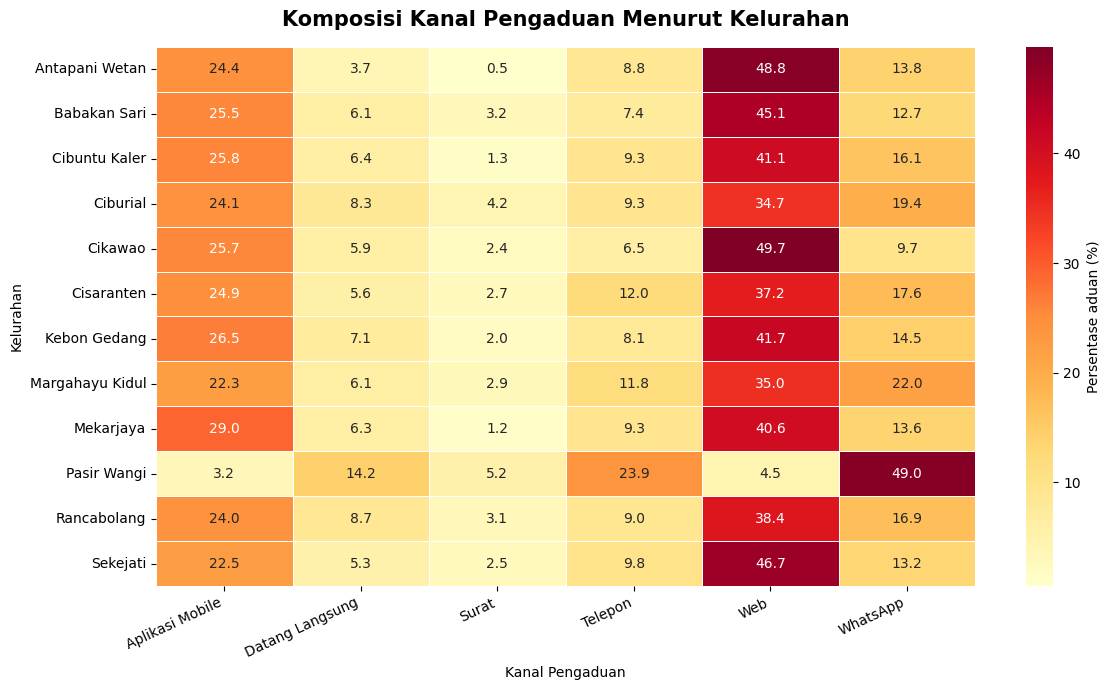

In [122]:

# ============================================================
# LANGKAH 3 - AUDIT KOMPOSISI KANAL PER KELURAHAN
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Menggunakan data aduan yang sudah tersedia
data_kanal = df_aduan[["kelurahan", "kanal"]].copy()

# Menangani nilai kosong
data_kanal["kelurahan"] = data_kanal["kelurahan"].fillna("Tidak diketahui")
data_kanal["kanal"] = data_kanal["kanal"].fillna("Tidak diketahui")

# Tabel jumlah aduan per kanal dan kelurahan
jumlah_kanal = pd.crosstab(
    data_kanal["kelurahan"],
    data_kanal["kanal"]
)

# Persentase kanal dalam masing-masing kelurahan
persentase_kanal = (
    jumlah_kanal
    .div(jumlah_kanal.sum(axis=1), axis=0)
    * 100
)

# Ringkasan kelurahan
ringkasan_kanal = pd.DataFrame({
    "jumlah_aduan": jumlah_kanal.sum(axis=1),
    "kanal_dominan": jumlah_kanal.idxmax(axis=1),
    "jumlah_kanal_dominan": jumlah_kanal.max(axis=1),
    "persentase_kanal_dominan": persentase_kanal.max(axis=1)
}).sort_values("jumlah_aduan", ascending=False)

print("=" * 70)
print("HASIL AUDIT KOMPOSISI KANAL PER KELURAHAN")
print("=" * 70)

print("\nJumlah seluruh aduan:", len(data_kanal))
print("Jumlah kelurahan:", data_kanal["kelurahan"].nunique())
print("Jenis kanal:", data_kanal["kanal"].nunique())
print("Jumlah data dengan kanal kosong sebelum penanganan:",
      df_aduan["kanal"].isna().sum())

print("\n1. JUMLAH ADUAN MENURUT KANAL")
display(jumlah_kanal)

print("\n2. PERSENTASE KANAL DALAM SETIAP KELURAHAN (%)")
display(persentase_kanal.round(2))

print("\n3. RINGKASAN KANAL DOMINAN")
display(ringkasan_kanal.round(2))

# Visualisasi komposisi kanal
plt.figure(figsize=(12, 7))

sns.heatmap(
    persentase_kanal,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Persentase aduan (%)"}
)

plt.title(
    "Komposisi Kanal Pengaduan Menurut Kelurahan",
    fontsize=15,
    fontweight="bold",
    pad=15
)
plt.xlabel("Kanal Pengaduan")
plt.ylabel("Kelurahan")
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Simpan visualisasi dan tabel jika direktori tersedia
if "OUTPUT_DIR" in globals():
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    plt.savefig(
        os.path.join(OUTPUT_DIR, "komposisi_kanal_per_kelurahan.png"),
        dpi=300,
        bbox_inches="tight"
    )

plt.show()

# Simpan tabel hasil
if "TABLE_DIR" in globals():
    os.makedirs(TABLE_DIR, exist_ok=True)
    jumlah_kanal.to_csv(
        os.path.join(TABLE_DIR, "jumlah_kanal_per_kelurahan.csv")
    )
    persentase_kanal.to_csv(
        os.path.join(TABLE_DIR, "persentase_kanal_per_kelurahan.csv")
    )
    ringkasan_kanal.to_csv(
        os.path.join(TABLE_DIR, "ringkasan_kanal_per_kelurahan.csv")
    )


## BAGIAN B

### PETA TEMATIK PERSEBARAN JUMLAH ADUAN

In [123]:
import geopandas as gpd

print("GEODATAFRAME YANG TERSEDIA:")
for nama, objek in list(globals().items()):
    if isinstance(objek, gpd.GeoDataFrame):
        print(f"\nNama variabel : {nama}")
        print(f"Jumlah baris  : {len(objek)}")
        print(f"Kolom         : {list(objek.columns)}")
        print(f"CRS           : {objek.crs}")

GEODATAFRAME YANG TERSEDIA:

Nama variabel : peta
Jumlah baris  : 12
Kolom         : ['kelurahan', 'kecamatan', 'jumlah_penduduk', 'luas_km2', 'geometry']
CRS           : EPSG:4326

Nama variabel : cocok
Jumlah baris  : 1
Kolom         : ['kelurahan', 'kecamatan', 'jumlah_penduduk', 'luas_km2', 'geometry']
CRS           : EPSG:4326

Nama variabel : data
Jumlah baris  : 823
Kolom         : ['id_aduan', 'lon', 'lat', 'kelurahan', 'pokok_masalah_final', 'geometry', 'x_meter', 'y_meter', 'cluster_id']
CRS           : EPSG:32748

Nama variabel : batas
Jumlah baris  : 12
Kolom         : ['kelurahan', 'kecamatan', 'jumlah_penduduk', 'luas_km2', 'geometry', '_key']
CRS           : EPSG:4326

Nama variabel : peta_visual
Jumlah baris  : 12
Kolom         : ['kelurahan', 'kecamatan', 'jumlah_penduduk', 'luas_km2', 'geometry', '_key', 'jumlah_aduan']
CRS           : EPSG:4326

Nama variabel : gdf
Jumlah baris  : 12
Kolom         : ['kelurahan', 'kecamatan', 'jumlah_penduduk', 'luas_km2', 'geometry'

DATA YANG DIGUNAKAN
Jumlah wilayah : 12
Jumlah aduan   : 5049

HASIL PENCOCOKAN
Wilayah dengan data aduan: 12
Wilayah tanpa data aduan: 0


,kelurahan,jumlah_aduan
0,Babakan Sari,756
1,Kebon Gedang,592
2,Mekarjaya,572
3,Sekejati,552
4,Cibuntu Kaler,453
5,Rancabolang,391
6,Antapani Wetan,377
7,Cikawao,370
8,Margahayu Kidul,314
9,Cisaranten,301


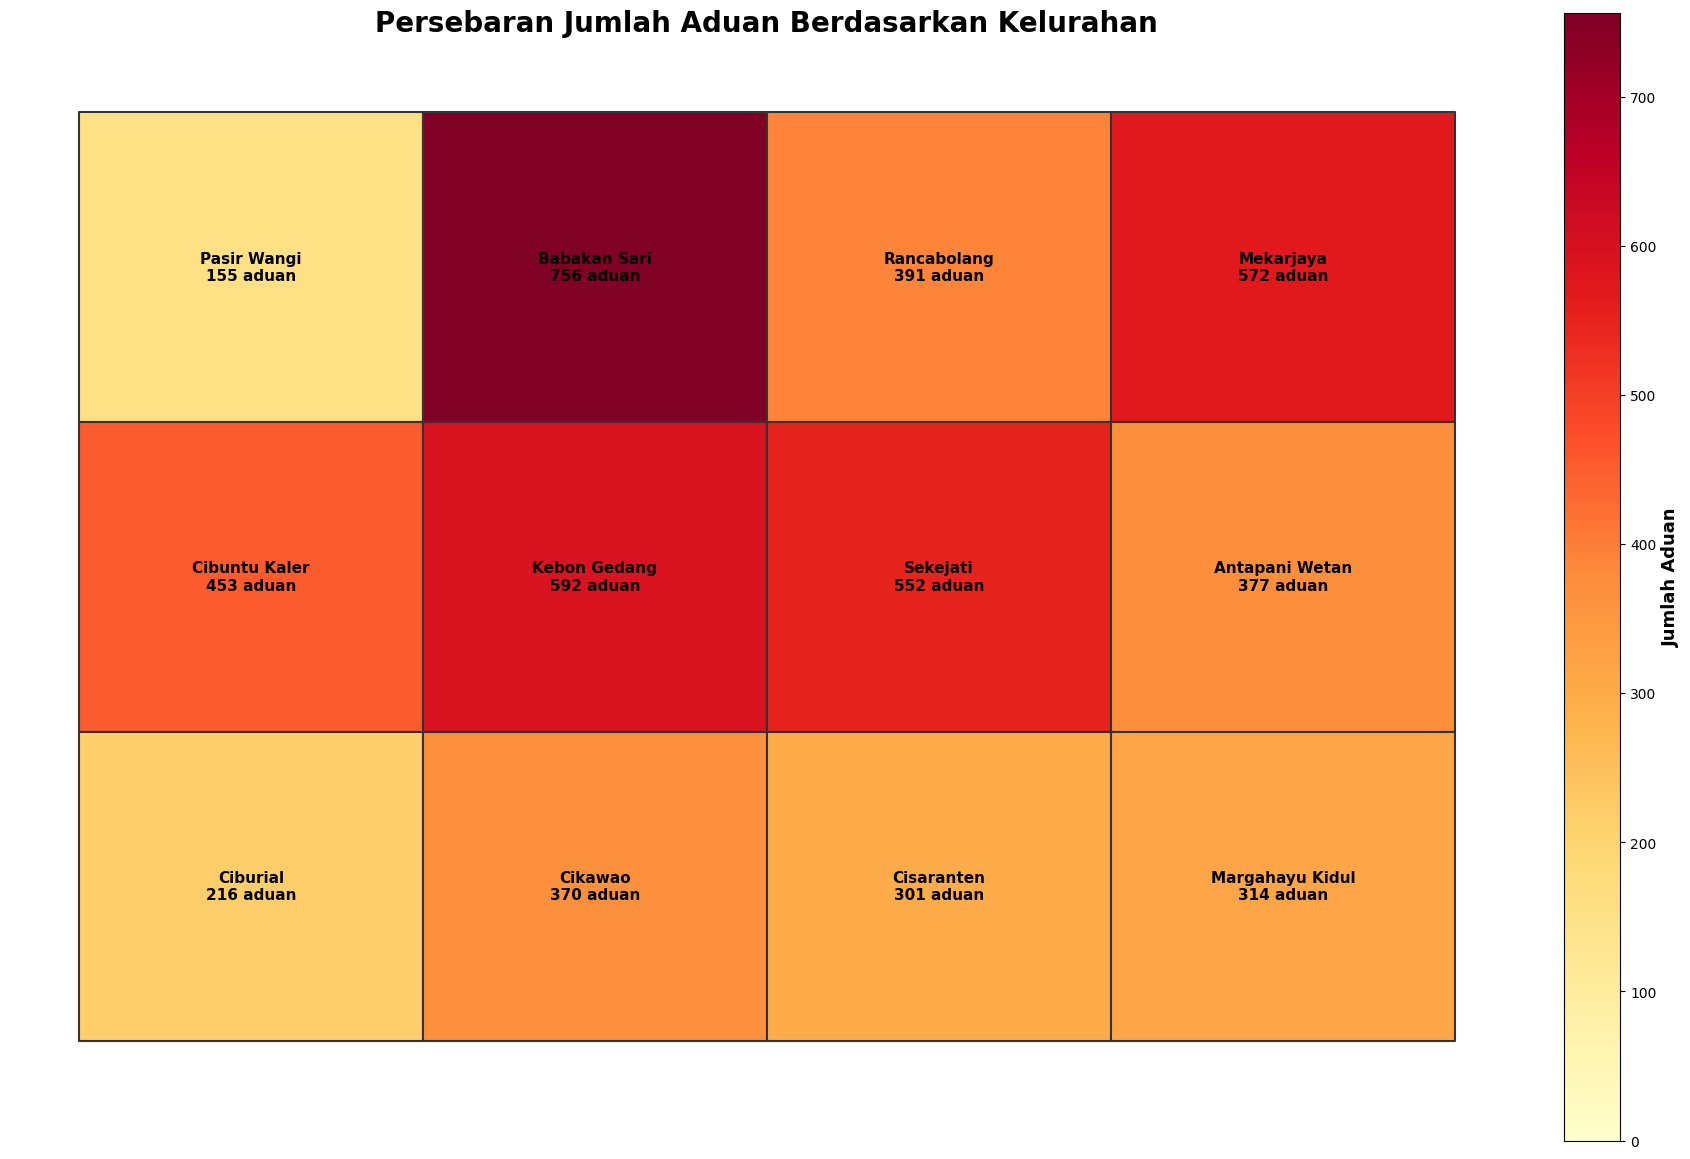


Visualisasi berhasil dibuat.
File tersimpan di: outputs/peta_persebaran_aduan_kelurahan.png


In [124]:

# ============================================================
# VISUALISASI PERSEBARAN ADUAN BERDASARKAN KELURAHAN
# Menggunakan poligon skematis dari GeoJSON
# ============================================================

import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. MEMERIKSA DATA YANG DIGUNAKAN
# ------------------------------------------------------------

if "peta" not in globals():
    raise NameError("GeoDataFrame 'peta' belum tersedia. Jalankan cell pemuatan GeoJSON terlebih dahulu.")

if "aduan_geo" in globals():
    sumber_aduan = aduan_geo.copy()
elif "df_aduan" in globals():
    sumber_aduan = df_aduan.copy()
else:
    raise NameError("Data aduan tidak ditemukan. Pastikan aduan_geo atau df_aduan sudah tersedia.")

peta_visual = peta.copy()

# Pastikan kolom yang diperlukan tersedia
if "kelurahan" not in peta_visual.columns:
    raise KeyError("Kolom 'kelurahan' tidak ditemukan pada data peta.")

if "kelurahan" not in sumber_aduan.columns:
    raise KeyError("Kolom 'kelurahan' tidak ditemukan pada data aduan.")

if "geometry" not in peta_visual.columns:
    raise KeyError("Kolom 'geometry' tidak ditemukan pada data peta.")

print("DATA YANG DIGUNAKAN")
print("Jumlah wilayah :", len(peta_visual))
print("Jumlah aduan   :", len(sumber_aduan))

# ------------------------------------------------------------
# 2. MENGHITUNG JUMLAH ADUAN PER KELURAHAN
# ------------------------------------------------------------

rekap_visual = (
    sumber_aduan
    .dropna(subset=["kelurahan"])
    .groupby("kelurahan")
    .size()
    .reset_index(name="jumlah_aduan")
)

# ------------------------------------------------------------
# 3. NORMALISASI NAMA KELURAHAN
# ------------------------------------------------------------

def normalisasi_nama(data):
    return (
        data.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
    )

peta_visual["_key"] = normalisasi_nama(
    peta_visual["kelurahan"]
)

rekap_visual["_key"] = normalisasi_nama(
    rekap_visual["kelurahan"]
)

# ------------------------------------------------------------
# 4. MENGGABUNGKAN JUMLAH ADUAN DENGAN POLIGON
# ------------------------------------------------------------

peta_visual = peta_visual.drop(
    columns=["jumlah_aduan"], errors="ignore"
).merge(
    rekap_visual[["_key", "jumlah_aduan"]],
    on="_key",
    how="left"
)

peta_visual["jumlah_aduan"] = (
    peta_visual["jumlah_aduan"].fillna(0).astype(int)
)

# Periksa hasil pencocokan
print("\nHASIL PENCOCOKAN")
print("Wilayah dengan data aduan:",
      (peta_visual["jumlah_aduan"] > 0).sum())
print("Wilayah tanpa data aduan:",
      (peta_visual["jumlah_aduan"] == 0).sum())

display(
    peta_visual[["kelurahan", "jumlah_aduan"]]
    .sort_values("jumlah_aduan", ascending=False)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 5. MEMBUAT VISUALISASI
# ------------------------------------------------------------

nilai = peta_visual["jumlah_aduan"]

vmax = max(nilai.max(), 1)
norm = mpl.colors.Normalize(vmin=0, vmax=vmax)
cmap = plt.cm.YlOrRd

fig, ax = plt.subplots(figsize=(17, 13))

peta_visual.plot(
    column="jumlah_aduan",
    cmap=cmap,
    norm=norm,
    linewidth=1.5,
    edgecolor="#333333",
    ax=ax,
    legend=False
)

# Label pada setiap poligon
for _, row in peta_visual.iterrows():

    if row.geometry is None or row.geometry.is_empty:
        continue

    titik = row.geometry.representative_point()

    nama = str(row["kelurahan"]).title()
    jumlah = int(row["jumlah_aduan"])

    ax.annotate(
        f"{nama}\n{jumlah:,} aduan",
        xy=(titik.x, titik.y),
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="black"
    )

# ------------------------------------------------------------
# 6. COLORBAR DAN JUDUL
# ------------------------------------------------------------

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.035,
    pad=0.025
)

cbar.set_label(
    "Jumlah Aduan",
    fontsize=13,
    fontweight="bold"
)

ax.set_title(
    "Persebaran Jumlah Aduan Berdasarkan Kelurahan",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.set_axis_off()
ax.set_aspect("equal")

plt.tight_layout()

# ------------------------------------------------------------
# 7. MENYIMPAN HASIL
# ------------------------------------------------------------

folder_output = Path("outputs")
folder_output.mkdir(parents=True, exist_ok=True)

lokasi_file = folder_output / "peta_persebaran_aduan_kelurahan.png"

plt.savefig(
    lokasi_file,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nVisualisasi berhasil dibuat.")
print("File tersimpan di:", lokasi_file)


In [125]:
# ============================================================
# PERBAIKAN VARIABEL GEOSPASIAL
# ============================================================

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

# 1. Pastikan data wilayah tersedia
if "peta" not in globals():
    raise NameError("Variabel peta belum tersedia.")

# 2. Konversi peta menjadi GeoDataFrame
if "geometry" not in peta.columns:
    raise KeyError("Kolom geometry tidak ditemukan pada peta.")

gdf = gpd.GeoDataFrame(
    peta.copy(),
    geometry="geometry",
    crs="EPSG:4326"
)

# 3. Pastikan data aduan tersedia
if "df_aduan" not in globals():
    raise NameError("Variabel df_aduan belum tersedia.")

# 4. Buat GeoDataFrame aduan
if "aduan_geo" not in globals():
    aduan_geo = gpd.GeoDataFrame(
        df_aduan.copy(),
        geometry=gpd.points_from_xy(
            df_aduan["lon"],
            df_aduan["lat"]
        ),
        crs="EPSG:4326"
    )
elif not isinstance(aduan_geo, gpd.GeoDataFrame):
    aduan_geo = gpd.GeoDataFrame(
        aduan_geo.copy(),
        geometry=gpd.points_from_xy(
            aduan_geo["lon"],
            aduan_geo["lat"]
        ),
        crs="EPSG:4326"
    )

# 5. Pastikan CRS sama
if aduan_geo.crs != gdf.crs:
    aduan_geo = aduan_geo.to_crs(gdf.crs)

# 6. Tetapkan kolom nama kelurahan
kolom_terbaik = "kelurahan"

# 7. Tampilkan pemeriksaan
print("=" * 55)
print("PEMERIKSAAN DATA GEOSPASIAL")
print("=" * 55)

print("Tipe gdf       :", type(gdf))
print("Jumlah wilayah :", len(gdf))
print("Kolom wilayah  :", list(gdf.columns))
print("CRS wilayah    :", gdf.crs)

print("\nTipe aduan_geo :", type(aduan_geo))
print("Jumlah aduan   :", len(aduan_geo))
print("CRS aduan      :", aduan_geo.crs)

print("\nKolom kelurahan:", kolom_terbaik)
print("=" * 55)

assert isinstance(gdf, gpd.GeoDataFrame)
assert isinstance(aduan_geo, gpd.GeoDataFrame)
assert gdf.crs == aduan_geo.crs

print("STATUS: DATA GEOSPASIAL SIAP DIGUNAKAN.")

PEMERIKSAAN DATA GEOSPASIAL
Tipe gdf       : <class 'geopandas.geodataframe.GeoDataFrame'>
Jumlah wilayah : 12
Kolom wilayah  : ['kelurahan', 'kecamatan', 'jumlah_penduduk', 'luas_km2', 'geometry']
CRS wilayah    : EPSG:4326

Tipe aduan_geo : <class 'geopandas.geodataframe.GeoDataFrame'>
Jumlah aduan   : 5049
CRS aduan      : EPSG:4326

Kolom kelurahan: kelurahan
STATUS: DATA GEOSPASIAL SIAP DIGUNAKAN.


In [126]:
# PEMERIKSAAN STRUKTUR DATA UNTUK VISUALISASI B.1

print("KOLOM aduan_geo:")
print(aduan_geo.columns.tolist())

print("\nKOLOM gdf:")
print(gdf.columns.tolist())

print("\nCONTOH DATA aduan_geo:")
display(aduan_geo.head(3))

print("\nCONTOH DATA gdf:")
display(gdf.head(3))

KOLOM aduan_geo:
['id_aduan', 'tanggal', 'kanal', 'kelurahan', 'kategori_dilaporkan', 'isi_aduan', 'lon', 'lat', 'status', 'kelurahan_key', 'kelurahan_wilayah', 'kecamatan', 'jumlah_penduduk', 'luas_km2', 'lon_pusat', 'lat_pusat', '_merge', 'geometry']

KOLOM gdf:
['kelurahan', 'kecamatan', 'jumlah_penduduk', 'luas_km2', 'geometry']

CONTOH DATA aduan_geo:


,id_aduan,tanggal,kanal,kelurahan,kategori_dilaporkan,isi_aduan,lon,lat,status,kelurahan_key,kelurahan_wilayah,kecamatan,jumlah_penduduk,luas_km2,lon_pusat,lat_pusat,_merge,geometry
0,ADU-002330,2026-03-16,Datang Langsung,Ciburial,Sampah,"Punten ngaganggu waktosna, Sampah menumpuk di ...",107.566695,-6.925499,Selesai,ciburial,Ciburial,Pasirwangi,15600,4.42,107.57,-6.925,both,POINT (107.5667 -6.9255)
1,ADU-004318,2025-09-12,Web,Sekejati,Ketertiban Umum,"Assalamualaikum Bapak/Ibu, Parkir liar di Jala...",107.614777,-6.915453,Selesai,sekejati,Sekejati,Rancasari,38600,4.42,107.61,-6.907,both,POINT (107.61478 -6.91545)
2,ADU-001600,2025-10-17,Web,Sekejati,Lain-lain,"Assalamualaikum Bapak/Ibu, Suara bising dari b...",107.618543,-6.912097,Diteruskan,sekejati,Sekejati,Rancasari,38600,4.42,107.61,-6.907,both,POINT (107.61854 -6.9121)



CONTOH DATA gdf:


,kelurahan,kecamatan,jumlah_penduduk,luas_km2,geometry
0,Pasir Wangi,Pasirwangi,41200,4.42,"POLYGON ((107.56 -6.88, 107.58 -6.88, 107.58 -..."
1,Cibuntu Kaler,Pasirwangi,33800,4.42,"POLYGON ((107.56 -6.898, 107.58 -6.898, 107.58..."
2,Ciburial,Pasirwangi,15600,4.42,"POLYGON ((107.56 -6.916, 107.58 -6.916, 107.58..."


### BAGIAN B.1: INTENSITAS ADUAN PER 1.000 PENDUDUK

HASIL INTENSITAS ADUAN PER 1.000 PENDUDUK


,kelurahan,jumlah_penduduk,jumlah_aduan,intensitas_aduan
4,Kebon Gedang,"18,300",592,32.35
7,Sekejati,"38,600",552,14.30
8,Cisaranten,"21,700",301,13.87
2,Ciburial,"15,600",216,13.85
5,Cikawao,"27,500",370,13.45
1,Cibuntu Kaler,"33,800",453,13.40
11,Margahayu Kidul,"24,800",314,12.66
10,Antapani Wetan,"30,200",377,12.48
3,Babakan Sari,"62,400",756,12.12
9,Mekarjaya,"52,100",572,10.98


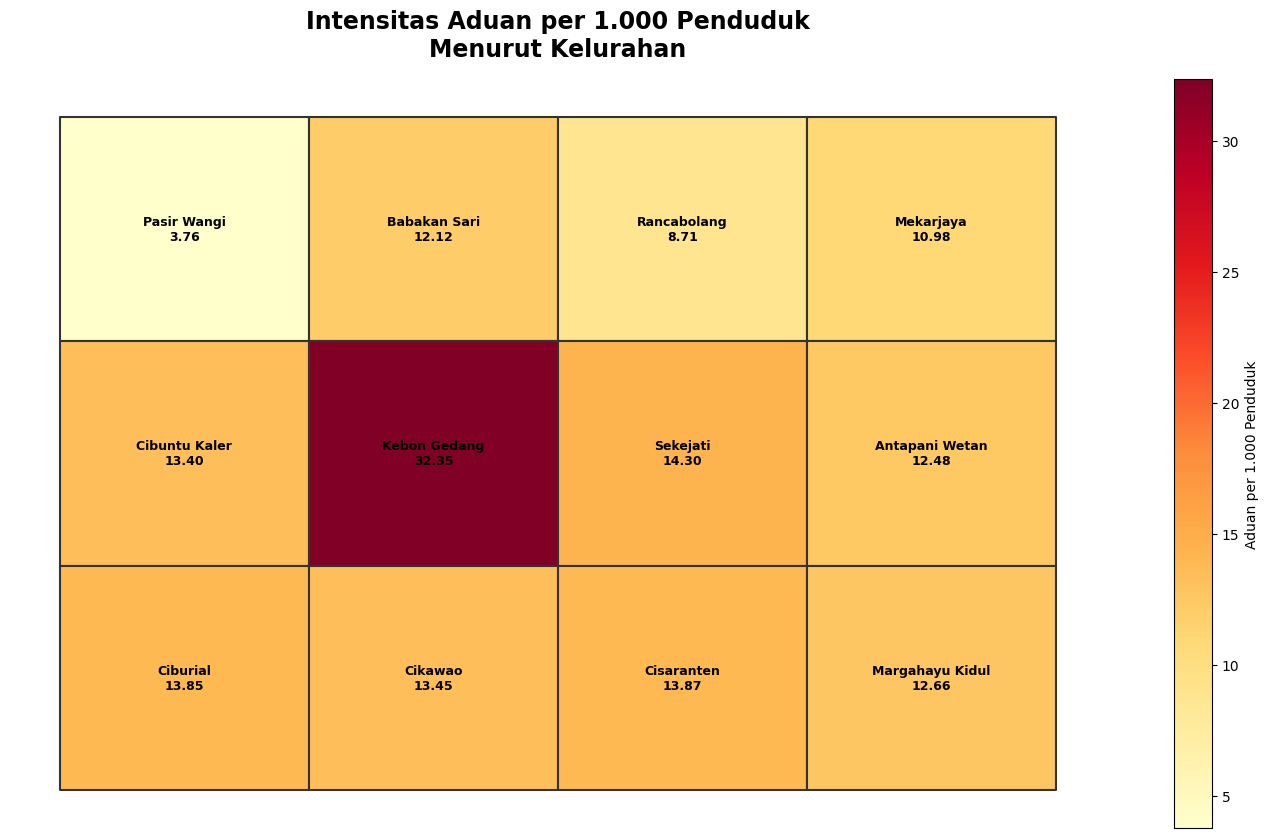


Visualisasi dan tabel berhasil disimpan.
Jumlah kelurahan: 12
Total aduan: 5049


In [127]:

# ============================================================
# BAGIAN B.1 — INTENSITAS ADUAN PER 1.000 PENDUDUK
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import geopandas as gpd

# ------------------------------------------------------------
# 1. Pastikan data tersedia
# ------------------------------------------------------------

if "gdf" not in globals():
    raise NameError("GeoDataFrame wilayah 'gdf' belum tersedia.")

if "aduan_geo" not in globals():
    raise NameError("Data aduan 'aduan_geo' belum tersedia.")

# Salin data agar tidak mengubah data utama
peta_b1 = gdf.copy()
data_aduan_b1 = aduan_geo.copy()

# ------------------------------------------------------------
# 2. Normalisasi nama kelurahan
# ------------------------------------------------------------

peta_b1["nama_key"] = (
    peta_b1["kelurahan"]
    .astype(str)
    .str.strip()
    .str.lower()
)

data_aduan_b1["nama_key"] = (
    data_aduan_b1["kelurahan"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# ------------------------------------------------------------
# 3. Hitung jumlah aduan setiap kelurahan
# ------------------------------------------------------------

jumlah_aduan_b1 = (
    data_aduan_b1
    .groupby("nama_key")
    .size()
    .reset_index(name="jumlah_aduan")
)

# ------------------------------------------------------------
# 4. Gabungkan data aduan dengan jumlah penduduk
# ------------------------------------------------------------

peta_b1 = peta_b1.merge(
    jumlah_aduan_b1,
    on="nama_key",
    how="left"
)

peta_b1["jumlah_aduan"] = (
    peta_b1["jumlah_aduan"].fillna(0)
)

# ------------------------------------------------------------
# 5. Hitung intensitas aduan per 1.000 penduduk
# ------------------------------------------------------------

peta_b1["intensitas_aduan"] = np.where(
    peta_b1["jumlah_penduduk"] > 0,
    (
        peta_b1["jumlah_aduan"]
        / peta_b1["jumlah_penduduk"]
    ) * 1000,
    np.nan
)

# ------------------------------------------------------------
# 6. Tampilkan hasil perhitungan
# ------------------------------------------------------------

rekap_b1 = peta_b1[
    [
        "kelurahan",
        "jumlah_penduduk",
        "jumlah_aduan",
        "intensitas_aduan"
    ]
].copy()

rekap_b1 = rekap_b1.sort_values(
    "intensitas_aduan",
    ascending=False
)

print("=" * 65)
print("HASIL INTENSITAS ADUAN PER 1.000 PENDUDUK")
print("=" * 65)

display(
    rekap_b1.style.format({
        "jumlah_penduduk": "{:,.0f}",
        "jumlah_aduan": "{:,.0f}",
        "intensitas_aduan": "{:.2f}"
    })
)

# ------------------------------------------------------------
# 7. Visualisasi persebaran intensitas aduan
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 11))

peta_b1.plot(
    column="intensitas_aduan",
    cmap="YlOrRd",
    linewidth=1.5,
    edgecolor="#333333",
    legend=True,
    legend_kwds={
        "label": "Aduan per 1.000 Penduduk",
        "shrink": 0.7
    },
    missing_kwds={
        "color": "lightgrey",
        "label": "Data tidak tersedia"
    },
    ax=ax
)

# Label setiap kelurahan
for _, row in peta_b1.iterrows():
    titik = row.geometry.representative_point()

    nilai = row["intensitas_aduan"]

    label = (
        f"{row['kelurahan']}\n"
        f"{nilai:.2f}"
        if pd.notna(nilai)
        else f"{row['kelurahan']}\nData tidak tersedia"
    )

    ax.annotate(
        label,
        xy=(titik.x, titik.y),
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="black"
    )

ax.set_title(
    "Intensitas Aduan per 1.000 Penduduk\n"
    "Menurut Kelurahan",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_axis_off()
ax.set_aspect("equal")

plt.tight_layout()

# ------------------------------------------------------------
# 8. Simpan hasil
# ------------------------------------------------------------

os.makedirs("outputs/tables", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)

rekap_b1.to_csv(
    "outputs/tables/intensitas_aduan_per_1000_penduduk.csv",
    index=False
)

plt.savefig(
    "outputs/figures/intensitas_aduan_per_1000_penduduk.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nVisualisasi dan tabel berhasil disimpan.")
print("Jumlah kelurahan:", len(peta_b1))
print("Total aduan:", int(peta_b1["jumlah_aduan"].sum()))


In [128]:

import pandas as pd

# Membaca hasil klasifikasi langsung dari GitHub
url_klasifikasi = (
    "https://raw.githubusercontent.com/"
    "dewaputufajar308/Tugas4-Geospatial-Visualization/"
    "main/hasil_klasifikasi_aduan.csv"
)

df_klasifikasi_spasial = pd.read_csv(url_klasifikasi)

# Menggabungkan hasil klasifikasi dengan data spasial
df_spasial = aduan_geo.merge(
    df_klasifikasi_spasial,
    on="id_aduan",
    how="left",
    validate="one_to_one"
)

# Ringkasan hasil
print("=" * 60)
print("HASIL PENGGABUNGAN DATA KLASIFIKASI DAN SPASIAL")
print("=" * 60)

print("Total data klasifikasi:", len(df_klasifikasi_spasial))
print("Total data spasial:", len(aduan_geo))
print("Total hasil penggabungan:", len(df_spasial))

print(
    "Kategori berhasil terhubung:",
    df_spasial["pokok_masalah_final"].notna().sum()
)

print(
    "Koordinat lengkap:",
    df_spasial[["lon", "lat"]].notna().all(axis=1).sum()
)

print("\nDistribusi pokok masalah:")
display(
    df_spasial["pokok_masalah_final"]
    .value_counts(dropna=False)
    .rename_axis("Pokok Masalah")
    .reset_index(name="Jumlah Aduan")
)

print("\nContoh hasil penggabungan:")
display(
    df_spasial[
        [
            "id_aduan",
            "kelurahan",
            "lon",
            "lat",
            "pokok_masalah_final"
        ]
    ].head()
)


HASIL PENGGABUNGAN DATA KLASIFIKASI DAN SPASIAL
Total data klasifikasi: 5049
Total data spasial: 5049
Total hasil penggabungan: 5049
Kategori berhasil terhubung: 5049
Koordinat lengkap: 4993

Distribusi pokok masalah:


,Pokok Masalah,Jumlah Aduan
0,Jalan Rusak,1129
1,Penerangan Jalan,947
2,Sampah,834
3,Drainase dan Banjir,577
4,Ketertiban Umum,517
5,Air Bersih,399
6,Fasilitas Umum,374
7,Lain-lain,202
8,Tidak dapat diklasifikasikan,70



Contoh hasil penggabungan:


,id_aduan,kelurahan,lon,lat,pokok_masalah_final
0,ADU-002330,Ciburial,107.566695,-6.925499,Sampah
1,ADU-004318,Sekejati,107.614777,-6.915453,Ketertiban Umum
2,ADU-001600,Sekejati,107.618543,-6.912097,Ketertiban Umum
3,ADU-003353,Cisaranten,107.611433,-6.928716,Penerangan Jalan
4,ADU-001236,Kebon Gedang,107.591213,-6.910023,Ketertiban Umum


### VISUALISASI SPASIAL BERDASARKAN POKOK MASALAH

In [129]:

# PEMERIKSAAN DATAFRAME HASIL KLASIFIKASI

import pandas as pd

print("DATAFRAME YANG TERSEDIA:")

for nama, objek in globals().copy().items():
    if isinstance(objek, pd.DataFrame):
        kolom = list(objek.columns)

        if (
            "id_aduan" in kolom
            or any(
                "pokok" in str(c).lower() or "masalah" in str(c).lower()
                for c in kolom
            )
        ):
            print(f"\nNama variabel : {nama}")
            print(f"Jumlah baris  : {len(objek)}")
            print(f"Kolom         : {kolom}")


DATAFRAME YANG TERSEDIA:

Nama variabel : aduan_df
Jumlah baris  : 5049
Kolom         : ['id_aduan', 'tanggal', 'kanal', 'kelurahan', 'kategori_dilaporkan', 'isi_aduan', 'lon', 'lat', 'status', 'kelurahan_key']

Nama variabel : penugasan_df
Jumlah baris  : 11626
Kolom         : ['id_aduan', 'urutan', 'dinas', 'tanggal_terima', 'tanggal_selesai', 'catatan']

Nama variabel : df
Jumlah baris  : 11626
Kolom         : ['id_aduan', 'urutan', 'dinas', 'tanggal_terima', 'tanggal_selesai', 'catatan']

Nama variabel : aduan_raw
Jumlah baris  : 5049
Kolom         : ['id_aduan', 'tanggal', 'kanal', 'kelurahan', 'kategori_dilaporkan', 'isi_aduan', 'lon', 'lat', 'status']

Nama variabel : aduan_geo
Jumlah baris  : 5049
Kolom         : ['id_aduan', 'tanggal', 'kanal', 'kelurahan', 'kategori_dilaporkan', 'isi_aduan', 'lon', 'lat', 'status', 'kelurahan_key', 'kelurahan_wilayah', 'kecamatan', 'jumlah_penduduk', 'luas_km2', 'lon_pusat', 'lat_pusat', '_merge', 'geometry']

Nama variabel : audit_spasial
Ju

JUMLAH DATA SPASIAL: 5049
JUMLAH WILAYAH: 12
JUMLAH TOPIK: 9

DAFTAR TOPIK:
- Air Bersih
- Drainase dan Banjir
- Fasilitas Umum
- Jalan Rusak
- Ketertiban Umum
- Lain-lain
- Penerangan Jalan
- Sampah
- Tidak dapat diklasifikasikan


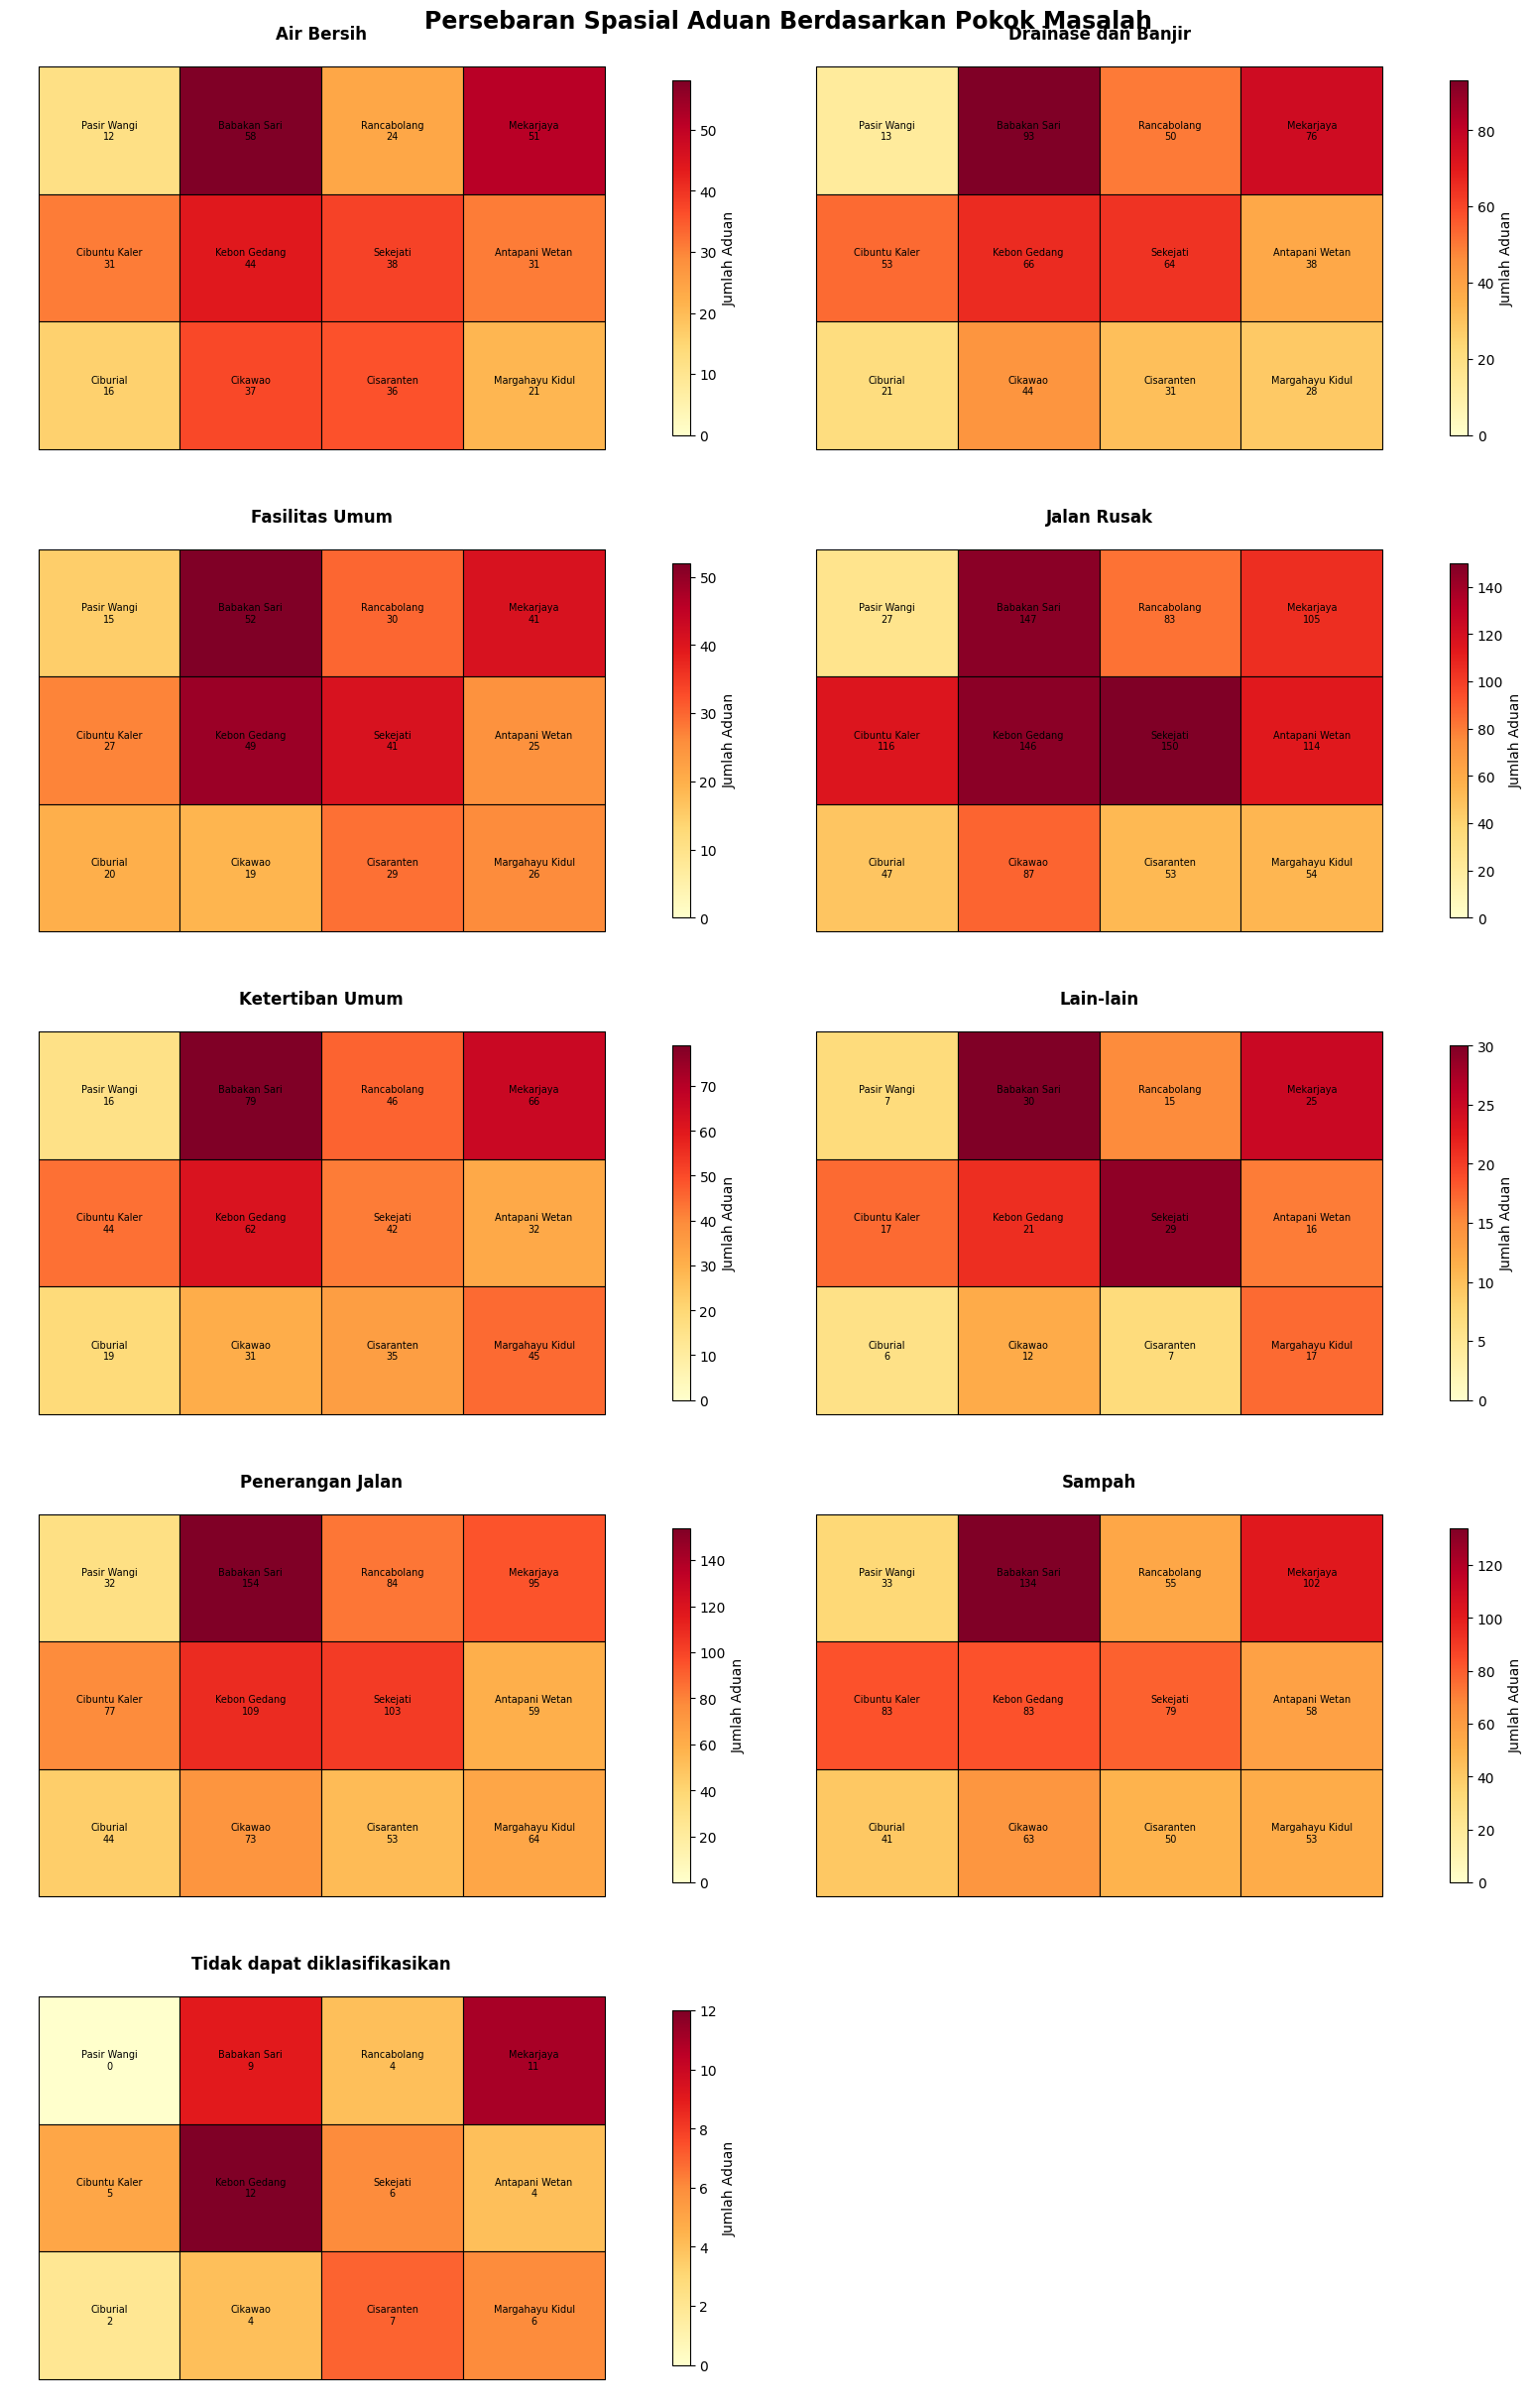


Visualisasi berhasil dibuat.
File: outputs/peta_spasial_berdasarkan_pokok_masalah.png


In [130]:

# ============================================================
# VISUALISASI SPASIAL BERDASARKAN POKOK MASALAH
# ============================================================

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# 1. Gunakan data yang sudah tersedia
wilayah = peta.copy()
data_spasial = df_spasial.copy()

# 2. Pastikan kolom yang dibutuhkan tersedia
assert "geometry" in wilayah.columns, "Geometry wilayah tidak ditemukan."
assert "pokok_masalah_final" in data_spasial.columns, "Kolom klasifikasi tidak ditemukan."

# 3. Gunakan nama kelurahan hasil pencocokan wilayah
kolom_wilayah = (
    "kelurahan_wilayah"
    if "kelurahan_wilayah" in data_spasial.columns
    else "kelurahan"
)

# Normalisasi nama kelurahan
wilayah["_key"] = (
    wilayah["kelurahan"].astype(str).str.strip().str.lower()
)

data_spasial["_key"] = (
    data_spasial[kolom_wilayah]
    .astype(str).str.strip().str.lower()
)

# 4. Rekap jumlah aduan berdasarkan kelurahan dan pokok masalah
rekap_topik = (
    data_spasial
    .dropna(subset=["pokok_masalah_final"])
    .groupby(["_key", "pokok_masalah_final"])
    .size()
    .reset_index(name="jumlah_aduan")
)

# 5. Ambil daftar topik
daftar_topik = sorted(
    rekap_topik["pokok_masalah_final"].unique()
)

print("JUMLAH DATA SPASIAL:", len(data_spasial))
print("JUMLAH WILAYAH:", len(wilayah))
print("JUMLAH TOPIK:", len(daftar_topik))
print("\nDAFTAR TOPIK:")
for topik in daftar_topik:
    print("-", topik)

# 6. Buat peta untuk setiap topik
n_topik = len(daftar_topik)
n_kolom = 2
n_baris = int(np.ceil(n_topik / n_kolom))

fig, axes = plt.subplots(
    n_baris,
    n_kolom,
    figsize=(16, 5 * n_baris)
)

axes = np.array(axes).reshape(-1)

for i, topik in enumerate(daftar_topik):

    ax = axes[i]

    rekap = rekap_topik[
        rekap_topik["pokok_masalah_final"] == topik
    ][["_key", "jumlah_aduan"]]

    peta_topik = wilayah.merge(
        rekap,
        on="_key",
        how="left"
    )

    peta_topik["jumlah_aduan"] = (
        peta_topik["jumlah_aduan"].fillna(0)
    )

    nilai_maks = max(
        1, peta_topik["jumlah_aduan"].max()
    )

    peta_topik.plot(
        column="jumlah_aduan",
        cmap="YlOrRd",
        vmin=0,
        vmax=nilai_maks,
        linewidth=0.8,
        edgecolor="black",
        legend=True,
        ax=ax,
        legend_kwds={
            "label": "Jumlah Aduan",
            "shrink": 0.75
        }
    )

    # Label nama kelurahan dan jumlah aduan
    for _, row in peta_topik.iterrows():

        titik = row.geometry.representative_point()

        ax.annotate(
            f"{row['kelurahan']}\n{int(row['jumlah_aduan'])}",
            xy=(titik.x, titik.y),
            ha="center",
            va="center",
            fontsize=7
        )

    ax.set_title(
        topik,
        fontsize=12,
        fontweight="bold"
    )

    ax.set_axis_off()
    ax.set_aspect("equal")

# 7. Sembunyikan subplot yang tidak digunakan
for j in range(n_topik, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Persebaran Spasial Aduan Berdasarkan Pokok Masalah",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

# 8. Simpan visualisasi
os.makedirs("outputs", exist_ok=True)

plt.savefig(
    "outputs/peta_spasial_berdasarkan_pokok_masalah.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nVisualisasi berhasil dibuat.")
print("File: outputs/peta_spasial_berdasarkan_pokok_masalah.png")


### BAGIAN B.2: IDENTIFIKASI GEROMBOLAN MASALAH

In [131]:

import pandas as pd
import geopandas as gpd
import numpy as np
from sklearn.cluster import DBSCAN

# 1. Menyiapkan data aduan
kolom = [
    "id_aduan", "lon", "lat",
    "kelurahan", "pokok_masalah_final"
]

df_cluster = df_spasial[kolom].copy()

# 2. Membersihkan koordinat yang tidak valid
df_cluster["lon"] = pd.to_numeric(df_cluster["lon"], errors="coerce")
df_cluster["lat"] = pd.to_numeric(df_cluster["lat"], errors="coerce")

df_cluster = df_cluster.dropna(
    subset=["lon", "lat", "kelurahan", "pokok_masalah_final"]
).copy()

df_cluster = df_cluster[
    (df_cluster["lon"] != 0) &
    (df_cluster["lat"] != 0) &
    (df_cluster["pokok_masalah_final"] != "Tidak dapat diklasifikasikan")
].copy()

# 3. Mengubah koordinat menjadi GeoDataFrame
gdf_cluster = gpd.GeoDataFrame(
    df_cluster,
    geometry=gpd.points_from_xy(
        df_cluster["lon"],
        df_cluster["lat"]
    ),
    crs="EPSG:4326"
)

# Proyeksi UTM zona 48S untuk wilayah Bandung
gdf_cluster = gdf_cluster.to_crs("EPSG:32748")

# 4. Pengelompokan DBSCAN per pokok masalah
EPS_METER = 300
MIN_SAMPLES = 5

hasil_cluster = []

for masalah, kelompok in gdf_cluster.groupby("pokok_masalah_final"):

    koordinat = np.column_stack([
        kelompok.geometry.x,
        kelompok.geometry.y
    ])

    dbscan = DBSCAN(
        eps=EPS_METER,
        min_samples=MIN_SAMPLES,
        metric="euclidean"
    )

    label = dbscan.fit_predict(koordinat)

    kelompok = kelompok.copy()
    kelompok["cluster_id"] = label

    # Simpan hasil setiap kelompok
    hasil_cluster.append(kelompok)

df_hasil_cluster = pd.concat(
    hasil_cluster,
    ignore_index=True
)

# 5. Mengidentifikasi gerombol yang melintasi kelurahan
rekap_cluster = (
    df_hasil_cluster[
        df_hasil_cluster["cluster_id"] != -1
    ]
    .groupby(["pokok_masalah_final", "cluster_id"])
    .agg(
        jumlah_aduan=("id_aduan", "count"),
        jumlah_kelurahan=("kelurahan", "nunique"),
        daftar_kelurahan=(
            "kelurahan",
            lambda x: ", ".join(sorted(x.unique()))
        )
    )
    .reset_index()
)

cluster_lintas = rekap_cluster[
    rekap_cluster["jumlah_kelurahan"] > 1
].copy()

# 6. Menampilkan hasil
print("=" * 65)
print("HASIL IDENTIFIKASI GEROMBOL MASALAH LINTAS KELURAHAN")
print("=" * 65)

print("Total aduan dengan koordinat valid:", len(gdf_cluster))
print("Total gerombol yang terbentuk:", len(rekap_cluster))
print("Gerombol lintas kelurahan:", len(cluster_lintas))

if len(cluster_lintas) > 0:
    display(
        cluster_lintas.sort_values(
            ["jumlah_aduan", "jumlah_kelurahan"],
            ascending=False
        ).reset_index(drop=True)
    )
else:
    print("Belum ditemukan gerombol lintas kelurahan.")

print("\nJumlah aduan yang tidak masuk gerombol:",
      (df_hasil_cluster["cluster_id"] == -1).sum())


HASIL IDENTIFIKASI GEROMBOL MASALAH LINTAS KELURAHAN
Total aduan dengan koordinat valid: 4904
Total gerombol yang terbentuk: 160
Gerombol lintas kelurahan: 67


,pokok_masalah_final,cluster_id,jumlah_aduan,jumlah_kelurahan,daftar_kelurahan
0,Jalan Rusak,0,750,11,"Antapani Wetan, Babakan Sari, Cibuntu Kaler, C..."
1,Penerangan Jalan,0,568,11,"Antapani Wetan, Babakan Sari, Cibuntu Kaler, C..."
2,Sampah,1,164,5,"Babakan Sari, Cibuntu Kaler, Kebon Gedang, Pas..."
3,Drainase dan Banjir,0,110,2,"Babakan Sari, Kebon Gedang"
4,Sampah,2,99,3,"Antapani Wetan, Mekarjaya, Rancabolang"
...,...,...,...,...,...
62,Drainase dan Banjir,16,5,2,"Antapani Wetan, Margahayu Kidul"
63,Jalan Rusak,12,5,2,"Cibuntu Kaler, Ciburial"
64,Ketertiban Umum,8,5,2,"Babakan Sari, Kebon Gedang"
65,Ketertiban Umum,23,5,2,"Mekarjaya, Rancabolang"



Jumlah aduan yang tidak masuk gerombol: 1433


In [132]:

from sklearn.cluster import DBSCAN
import numpy as np
import pandas as pd

daftar_eps = [100, 150, 200, 300]
hasil_uji = []

for eps in daftar_eps:

    jumlah_gerombol = 0
    jumlah_lintas = 0
    jumlah_aduan_lintas = 0
    gerombol_terbesar = 0

    for masalah, kelompok in gdf_cluster.groupby(
        "pokok_masalah_final"
    ):

        koordinat = np.column_stack([
            kelompok.geometry.x,
            kelompok.geometry.y
        ])

        label = DBSCAN(
            eps=eps,
            min_samples=5,
            metric="euclidean"
        ).fit_predict(koordinat)

        kelompok_uji = kelompok.copy()
        kelompok_uji["cluster_uji"] = label

        cluster_valid = kelompok_uji[
            kelompok_uji["cluster_uji"] != -1
        ]

        jumlah_gerombol += cluster_valid.groupby(
            "cluster_uji"
        ).ngroups

        rekap = (
            cluster_valid.groupby("cluster_uji")
            .agg(
                jumlah_aduan=("id_aduan", "count"),
                jumlah_kelurahan=("kelurahan", "nunique")
            )
        )

        if len(rekap) > 0:
            gerombol_terbesar = max(
                gerombol_terbesar,
                rekap["jumlah_aduan"].max()
            )

            lintas = rekap[
                rekap["jumlah_kelurahan"] > 1
            ]

            jumlah_lintas += len(lintas)
            jumlah_aduan_lintas += lintas[
                "jumlah_aduan"
            ].sum()

    hasil_uji.append({
        "eps_meter": eps,
        "total_gerombol": jumlah_gerombol,
        "gerombol_lintas_kelurahan": jumlah_lintas,
        "aduan_dalam_gerombol_lintas": jumlah_aduan_lintas,
        "ukuran_gerombol_terbesar": gerombol_terbesar
    })

tabel_uji_parameter = pd.DataFrame(hasil_uji)

print("PERBANDINGAN PARAMETER DBSCAN")
display(tabel_uji_parameter)


PERBANDINGAN PARAMETER DBSCAN


,eps_meter,total_gerombol,gerombol_lintas_kelurahan,aduan_dalam_gerombol_lintas,ukuran_gerombol_terbesar
0,100,34,13,103,20
1,150,77,20,298,33
2,200,158,34,625,232
3,300,160,67,2633,750


HASIL CLUSTERING DBSCAN - EPS 150 METER
Total aduan dianalisis: 4904
Total aduan dalam gerombol: 676
Total gerombol lintas kelurahan: 20
Total aduan dalam gerombol lintas kelurahan: 298

20 GEROMBOL LINTAS KELURAHAN TERBESAR:


,pokok_masalah_final,cluster_id,jumlah_aduan,jumlah_kelurahan,daftar_kelurahan
0,Jalan Rusak,3,33,4,"Babakan Sari, Kebon Gedang, Rancabolang, Sekejati"
1,Jalan Rusak,1,31,2,"Babakan Sari, Kebon Gedang"
2,Jalan Rusak,8,30,4,"Antapani Wetan, Mekarjaya, Rancabolang, Sekejati"
3,Jalan Rusak,9,29,2,"Rancabolang, Sekejati"
4,Jalan Rusak,12,27,2,"Antapani Wetan, Mekarjaya"
5,Jalan Rusak,11,18,2,"Cibuntu Kaler, Kebon Gedang"
6,Jalan Rusak,13,18,2,"Rancabolang, Sekejati"
7,Jalan Rusak,16,16,2,"Antapani Wetan, Mekarjaya"
8,Jalan Rusak,5,14,2,"Babakan Sari, Kebon Gedang"
9,Jalan Rusak,18,11,2,"Babakan Sari, Kebon Gedang"


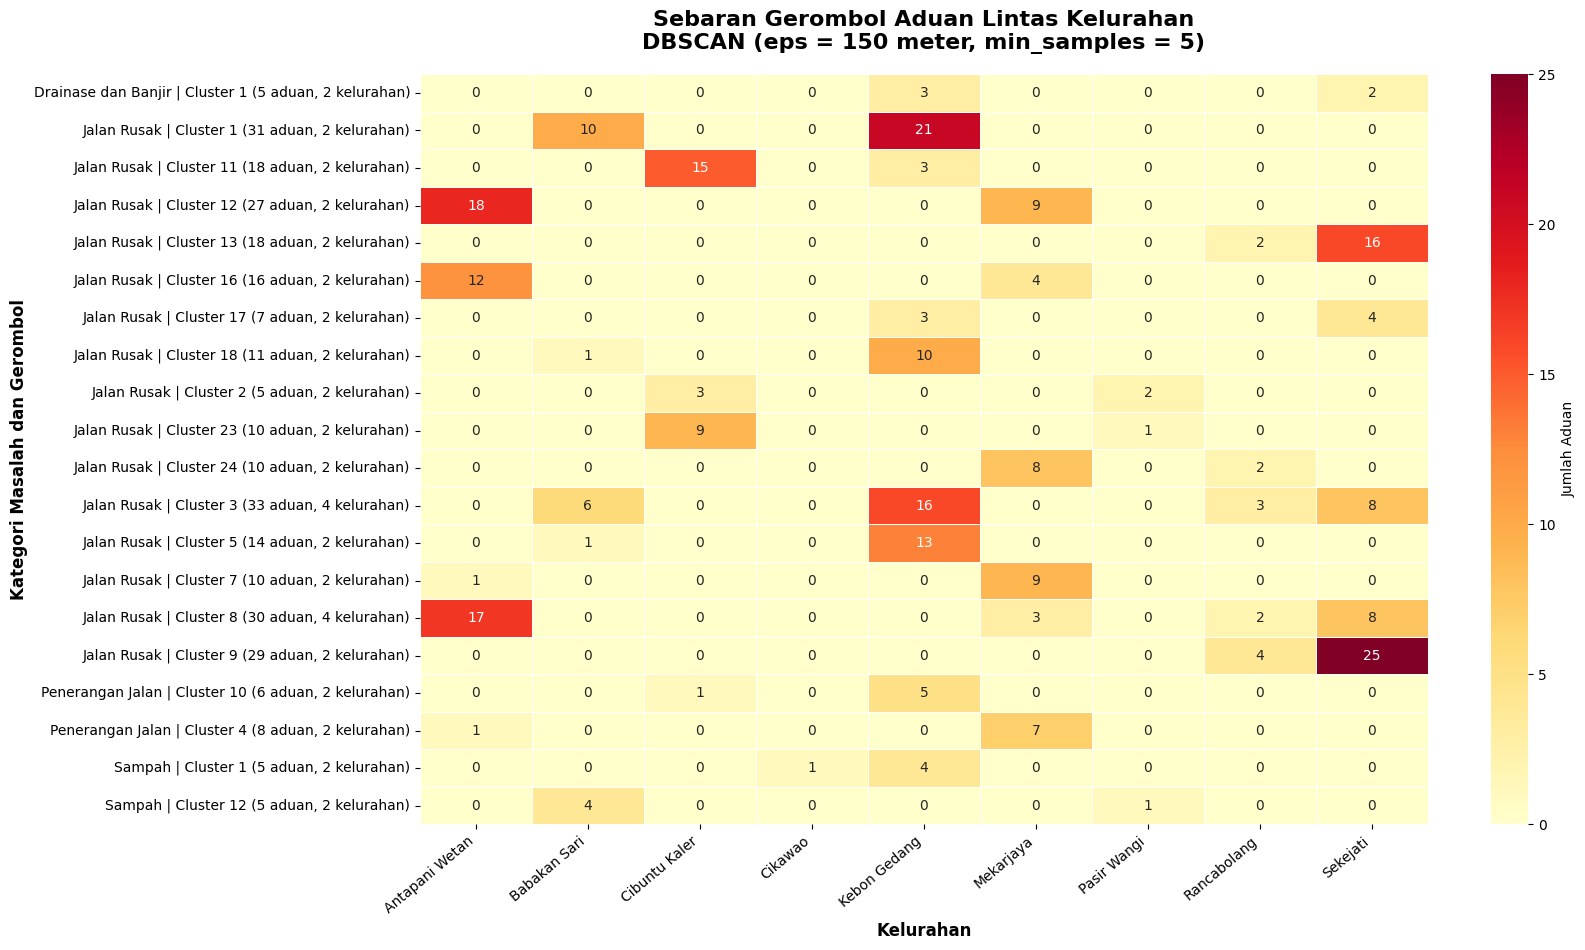


RINGKASAN PARAMETER ANALISIS
---------------------------------------------
Algoritma          : DBSCAN
Epsilon            : 150 meter
Min samples        : 5
Sistem koordinat   : EPSG:32748
Pengelompokan      : Per pokok masalah
Kriteria lintas    : Lebih dari 1 kelurahan
Jumlah gerombol    : 77
Gerombol lintas    : 20


In [133]:

# ============================================================
# B.2 - CLUSTERING ULANG DAN VISUALISASI GEROMBOL LINTAS KELURAHAN
# Parameter: eps = 150 meter, min_samples = 5
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN
from pyproj import Transformer

# ------------------------------------------------------------
# 1. PERSIAPAN DATA
# ------------------------------------------------------------

df_cluster_input = df_hasil_cluster.copy()

# Pastikan kolom yang diperlukan tersedia
kolom_wajib = [
    "id_aduan", "lon", "lat",
    "kelurahan", "pokok_masalah_final"
]

for kolom in kolom_wajib:
    if kolom not in df_cluster_input.columns:
        raise ValueError(f"Kolom {kolom} tidak ditemukan.")

# Hapus hasil clustering lama agar tidak digunakan kembali
df_cluster_input = df_cluster_input.drop(
    columns=["cluster_id"], errors="ignore"
)

df_cluster_input = df_cluster_input.dropna(
    subset=["lon", "lat", "kelurahan", "pokok_masalah_final"]
).copy()

# ------------------------------------------------------------
# 2. PROYEKSI KOORDINAT KE EPSG:32748
# ------------------------------------------------------------

transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32748",
    always_xy=True
)

x, y = transformer.transform(
    df_cluster_input["lon"].values,
    df_cluster_input["lat"].values
)

df_cluster_input["x_meter"] = x
df_cluster_input["y_meter"] = y

# ------------------------------------------------------------
# 3. CLUSTERING DBSCAN PER POKOK MASALAH
# ------------------------------------------------------------

EPS = 150
MIN_SAMPLES = 5

hasil_cluster = []

for kategori, data in df_cluster_input.groupby(
    "pokok_masalah_final"
):
    data = data.copy()

    koordinat = data[["x_meter", "y_meter"]].values

    model = DBSCAN(
        eps=EPS,
        min_samples=MIN_SAMPLES,
        metric="euclidean"
    )

    data["cluster_id"] = model.fit_predict(koordinat)

    hasil_cluster.append(data)

df_hasil_cluster_150 = pd.concat(
    hasil_cluster,
    ignore_index=True
)

# ------------------------------------------------------------
# 4. IDENTIFIKASI GEROMBOL LINTAS KELURAHAN
# ------------------------------------------------------------

df_non_noise = df_hasil_cluster_150[
    df_hasil_cluster_150["cluster_id"] != -1
].copy()

rekap_cluster = (
    df_non_noise
    .groupby(["pokok_masalah_final", "cluster_id"])
    .agg(
        jumlah_aduan=("id_aduan", "count"),
        jumlah_kelurahan=("kelurahan", "nunique"),
        daftar_kelurahan=(
            "kelurahan",
            lambda x: ", ".join(sorted(x.unique()))
        )
    )
    .reset_index()
)

# Hanya gerombol yang melintasi batas kelurahan
kelompok = (
    rekap_cluster[
        rekap_cluster["jumlah_kelurahan"] > 1
    ]
    .sort_values("jumlah_aduan", ascending=False)
    .reset_index(drop=True)
)

print("=" * 65)
print("HASIL CLUSTERING DBSCAN - EPS 150 METER")
print("=" * 65)
print("Total aduan dianalisis:", len(df_hasil_cluster_150))
print("Total aduan dalam gerombol:", len(df_non_noise))
print("Total gerombol lintas kelurahan:", len(kelompok))
print(
    "Total aduan dalam gerombol lintas kelurahan:",
    kelompok["jumlah_aduan"].sum()
)

print("\n20 GEROMBOL LINTAS KELURAHAN TERBESAR:")
display(kelompok.head(20))

# ------------------------------------------------------------
# 5. MENYIAPKAN DATA HEATMAP
# ------------------------------------------------------------

top_cluster = kelompok.head(20).copy()

# Buat identitas gerombol yang unik berdasarkan kategori
top_cluster["label_cluster"] = (
    top_cluster["pokok_masalah_final"]
    + " | Cluster "
    + top_cluster["cluster_id"].astype(str)
    + " ("
    + top_cluster["jumlah_aduan"].astype(str)
    + " aduan, "
    + top_cluster["jumlah_kelurahan"].astype(str)
    + " kelurahan)"
)

data_heatmap = df_non_noise.merge(
    top_cluster[
        ["pokok_masalah_final", "cluster_id", "label_cluster"]
    ],
    on=["pokok_masalah_final", "cluster_id"],
    how="inner"
)

matriks_heatmap = pd.pivot_table(
    data_heatmap,
    index="label_cluster",
    columns="kelurahan",
    values="id_aduan",
    aggfunc="count",
    fill_value=0
)

# Urutkan kolom kelurahan secara alfabetis
matriks_heatmap = matriks_heatmap.reindex(
    sorted(matriks_heatmap.columns),
    axis=1
)

# ------------------------------------------------------------
# 6. VISUALISASI HEATMAP
# ------------------------------------------------------------

tinggi = max(8, len(matriks_heatmap) * 0.48)

fig, ax = plt.subplots(
    figsize=(17, tinggi)
)

sns.heatmap(
    matriks_heatmap,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Jumlah Aduan"},
    ax=ax
)

ax.set_title(
    "Sebaran Gerombol Aduan Lintas Kelurahan\n"
    "DBSCAN (eps = 150 meter, min_samples = 5)",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Kelurahan", fontsize=12, fontweight="bold")
ax.set_ylabel("Kategori Masalah dan Gerombol", fontsize=12, fontweight="bold")

plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. RINGKASAN PARAMETER
# ------------------------------------------------------------

print("\nRINGKASAN PARAMETER ANALISIS")
print("-" * 45)
print("Algoritma          : DBSCAN")
print("Epsilon            :", EPS, "meter")
print("Min samples        :", MIN_SAMPLES)
print("Sistem koordinat   : EPSG:32748")
print("Pengelompokan      : Per pokok masalah")
print("Kriteria lintas    : Lebih dari 1 kelurahan")
print("Jumlah gerombol    :", len(rekap_cluster))
print("Gerombol lintas    :", len(kelompok))


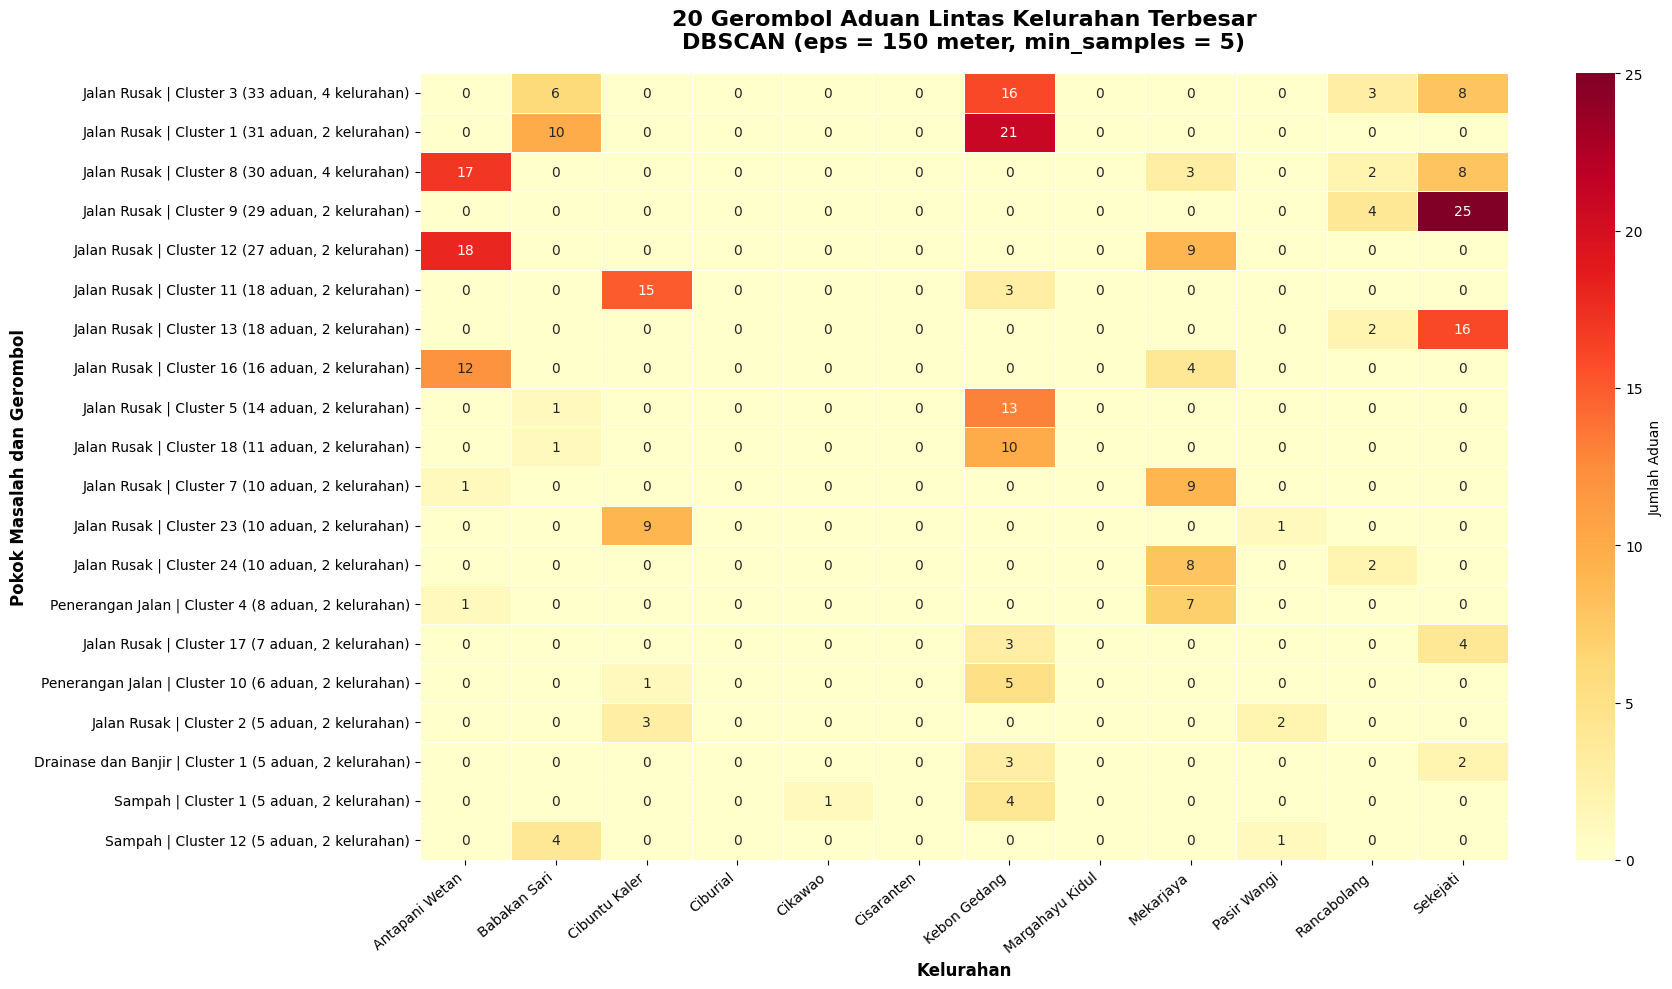

In [134]:

# ============================================================
# PENYEMPURNAAN HEATMAP B.2
# Mengurutkan gerombol berdasarkan jumlah aduan
# dan menampilkan seluruh 12 kelurahan
# ============================================================

# Urutan gerombol mengikuti jumlah aduan terbesar
urutan_baris = top_cluster["label_cluster"].tolist()

# Ambil seluruh nama kelurahan dari data wilayah
seluruh_kelurahan = sorted(
    df_wilayah["kelurahan"].dropna().unique()
)

# Susun ulang matriks heatmap
heatmap_final = matriks_heatmap.reindex(
    index=urutan_baris,
    columns=seluruh_kelurahan,
    fill_value=0
)

# Visualisasi
fig, ax = plt.subplots(figsize=(18, 10))

sns.heatmap(
    heatmap_final,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Jumlah Aduan"},
    ax=ax
)

ax.set_title(
    "20 Gerombol Aduan Lintas Kelurahan Terbesar\n"
    "DBSCAN (eps = 150 meter, min_samples = 5)",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Kelurahan", fontsize=12, fontweight="bold")
ax.set_ylabel("Pokok Masalah dan Gerombol", fontsize=12, fontweight="bold")

plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


### AUDIT KECOCOKAN KELURAHAN DENGAN KOORDINAT

In [135]:

# ============================================================
# AUDIT KECOCOKAN KELURAHAN DENGAN KOORDINAT
# ============================================================

import pandas as pd
import geopandas as gpd
import numpy as np

print("=" * 65)
print("AUDIT KECOCOKAN KELURAHAN DENGAN KOORDINAT")
print("=" * 65)

# 1. Pastikan data utama tersedia
if "aduan_df" not in globals():
    raise NameError("DataFrame aduan_df tidak ditemukan.")

if "peta" not in globals():
    raise NameError("DataFrame peta tidak ditemukan.")

# 2. Salin data agar data asli tidak berubah
audit_spasial = aduan_df.copy()
peta_audit = peta.copy()

# 3. Pastikan data peta merupakan GeoDataFrame
if not isinstance(peta_audit, gpd.GeoDataFrame):
    raise TypeError("Variabel peta harus berupa GeoDataFrame.")

# 4. Buat kolom kunci kelurahan pada kedua data
def normalisasi_kelurahan(kolom):
    return (
        kolom.astype("string")
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
    )

audit_spasial["kelurahan_key"] = normalisasi_kelurahan(
    audit_spasial["kelurahan"]
)

peta_audit["kelurahan_key"] = normalisasi_kelurahan(
    peta_audit["kelurahan"]
)

# 5. Periksa dan konversi koordinat
audit_spasial["lon"] = pd.to_numeric(
    audit_spasial["lon"], errors="coerce"
)
audit_spasial["lat"] = pd.to_numeric(
    audit_spasial["lat"], errors="coerce"
)

koordinat_kosong = (
    audit_spasial["lon"].isna() |
    audit_spasial["lat"].isna()
)

koordinat_nol = (
    (audit_spasial["lon"] == 0) |
    (audit_spasial["lat"] == 0)
)

# 6. Buat status awal koordinat
audit_spasial["status_koordinat"] = "Valid"

audit_spasial.loc[
    koordinat_kosong, "status_koordinat"
] = "Koordinat kosong"

audit_spasial.loc[
    ~koordinat_kosong & koordinat_nol,
    "status_koordinat"
] = "Koordinat nol"

# 7. Siapkan data koordinat yang dapat diperiksa
data_valid = audit_spasial[
    audit_spasial["status_koordinat"] == "Valid"
].copy()

# Periksa rentang koordinat geografis
rentang_valid = (
    data_valid["lon"].between(-180, 180) &
    data_valid["lat"].between(-90, 90)
)

data_valid = data_valid[rentang_valid].copy()

# Koordinat yang di luar rentang dianggap tidak valid
audit_spasial.loc[
    audit_spasial.index.difference(data_valid.index)
    .difference(audit_spasial.index[
        audit_spasial["status_koordinat"] != "Valid"
    ]),
    "status_koordinat"
] = "Koordinat tidak valid"

# 8. Ubah koordinat aduan menjadi titik geografis
aduan_titik = gpd.GeoDataFrame(
    data_valid,
    geometry=gpd.points_from_xy(
        data_valid["lon"],
        data_valid["lat"]
    ),
    crs="EPSG:4326"
)

# Samakan CRS
if peta_audit.crs is None:
    raise ValueError("CRS pada data peta belum ditentukan.")

aduan_titik = aduan_titik.to_crs(peta_audit.crs)

# 9. Cocokkan titik koordinat dengan poligon kelurahan
hasil_join = gpd.sjoin(
    aduan_titik,
    peta_audit[["kelurahan", "kelurahan_key", "geometry"]],
    how="left",
    predicate="within"
)

# Jika ada titik yang tepat berada di batas poligon,
# coba periksa kembali menggunakan intersects
belum_cocok = hasil_join["kelurahan_key_right"].isna()

if belum_cocok.any():
    titik_batas = aduan_titik.loc[
        hasil_join.loc[belum_cocok].index
    ]

    hasil_batas = gpd.sjoin(
        titik_batas,
        peta_audit[["kelurahan", "kelurahan_key", "geometry"]],
        how="left",
        predicate="intersects"
    )

    hasil_join.loc[
        hasil_batas.index, "kelurahan_key_right"
    ] = hasil_batas["kelurahan_key_right"]

    hasil_join.loc[
        hasil_batas.index, "kelurahan_dari_koordinat"
    ] = hasil_batas["kelurahan_right"]

# 10. Simpan hasil kelurahan dari koordinat
if "kelurahan_right" in hasil_join.columns:
    hasil_join["kelurahan_dari_koordinat"] = (
        hasil_join["kelurahan_right"]
    )

hasil_join = hasil_join[
    ~hasil_join.index.duplicated(keep="first")
]

audit_spasial["kelurahan_dari_koordinat"] = np.nan
audit_spasial["kelurahan_key_koordinat"] = np.nan

audit_spasial.loc[
    hasil_join.index, "kelurahan_dari_koordinat"
] = hasil_join["kelurahan_dari_koordinat"]

audit_spasial.loc[
    hasil_join.index, "kelurahan_key_koordinat"
] = hasil_join["kelurahan_key_right"]

# 11. Tentukan kecocokan kelurahan
audit_spasial["status_kecocokan"] = "Sesuai"

audit_spasial.loc[
    audit_spasial["status_koordinat"] != "Valid",
    "status_kecocokan"
] = "Tidak dapat diperiksa"

audit_spasial.loc[
    (audit_spasial["status_koordinat"] == "Valid") &
    (audit_spasial["kelurahan_key_koordinat"].isna()),
    "status_kecocokan"
] = "Tidak dapat diperiksa"

audit_spasial.loc[
    (audit_spasial["status_koordinat"] == "Valid") &
    (audit_spasial["kelurahan_key_koordinat"].notna()) &
    (audit_spasial["kelurahan_key"] !=
     audit_spasial["kelurahan_key_koordinat"]),
    "status_kecocokan"
] = "Tidak sesuai"

# 12. Tampilkan hasil audit
print("\nSTATUS KOORDINAT:")
display(
    audit_spasial["status_koordinat"]
    .value_counts()
    .rename_axis("Jenis Temuan")
    .reset_index(name="Jumlah Aduan")
)

print("\nKECOCOKAN KELURAHAN:")
display(
    audit_spasial["status_kecocokan"]
    .value_counts()
    .rename_axis("Status")
    .reset_index(name="Jumlah Aduan")
)

print("\nCONTOH KELURAHAN YANG TIDAK SESUAI:")
kolom_tampil = [
    "id_aduan",
    "kelurahan",
    "kelurahan_dari_koordinat",
    "lon",
    "lat"
]

display(
    audit_spasial.loc[
        audit_spasial["status_kecocokan"] == "Tidak sesuai",
        kolom_tampil
    ].head(20)
)

print("\nAUDIT SELESAI.")
print("Total data:", len(audit_spasial))


AUDIT KECOCOKAN KELURAHAN DENGAN KOORDINAT

STATUS KOORDINAT:


/tmp/ipykernel_1340/116575566.py:158: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['Ciburial' 'Sekejati' 'Sekejati' ... 'Cisaranten' 'Cibuntu Kaler'
 'Cibuntu Kaler']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  audit_spasial.loc[
/tmp/ipykernel_1340/116575566.py:162: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '<StringArray>
[      'ciburial',       'sekejati',       'sekejati',     'cisaranten',
   'kebon gedang',        'cikawao',   'babakan sari',      'mekarjaya',
     'cisaranten',   'babakan sari',
 ...
 'antapani wetan',  'cibuntu kaler',  'cibuntu kaler',       'ciburial',
    'pasir wangi',   'kebon gedang',    'rancabolang',     'cisaranten',
  'cibuntu kaler',  'cibuntu kaler']
Length: 4973, dtype: string' has dtype incompatible with float64, please explicitly c

,Jenis Temuan,Jumlah Aduan
0,Valid,4973
1,Koordinat kosong,56
2,Koordinat nol,20



KECOCOKAN KELURAHAN:


,Status,Jumlah Aduan
0,Sesuai,4874
1,Tidak sesuai,99
2,Tidak dapat diperiksa,76



CONTOH KELURAHAN YANG TIDAK SESUAI:


,id_aduan,kelurahan,kelurahan_dari_koordinat,lon,lat
37,ADU-001096,Cibuntu Kaler,Pasir Wangi,107.569075,-6.897505
57,ADU-000329,Kebon Gedang,Babakan Sari,107.585296,-6.897579
161,ADU-000638,Antapani Wetan,Mekarjaya,107.621880,-6.897890
233,ADU-000273,Kebon Gedang,Babakan Sari,107.580314,-6.897394
284,ADU-004530,Antapani Wetan,Mekarjaya,107.627583,-6.896647
354,ADU-000375,Antapani Wetan,Mekarjaya,107.636213,-6.897921
410,ADU-003815,Sekejati,Rancabolang,107.605852,-6.897715
643,ADU-004470,Sekejati,Rancabolang,107.618657,-6.897796
704,ADU-002174,Cibuntu Kaler,Pasir Wangi,107.578323,-6.896993
789,ADU-003550,Cibuntu Kaler,Pasir Wangi,107.565338,-6.897527



AUDIT SELESAI.
Total data: 5049


### Analisis gerombol (clustering) secara geografis.

PEMERIKSAAN JARAK ANTAR TITIK
Jumlah titik yang digunakan: 4973
Tetangga yang diperiksa: 9

Distribusi jarak ke tetangga ke-10:
count    4973.000000
mean      170.352883
std        50.001978
min         0.000000
25%       136.943686
50%       163.532022
75%       195.029521
90%       232.627060
95%       261.077857
max       479.366251
dtype: float64


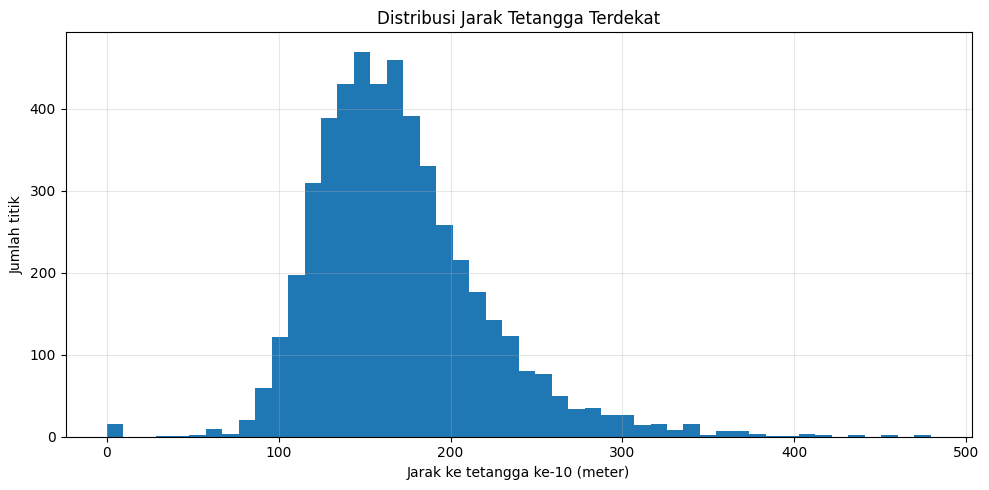

In [136]:
# PEMERIKSAAN JARAK ANTAR TITIK UNTUK MENENTUKAN PARAMETER DBSCAN

import numpy as np
from sklearn.neighbors import NearestNeighbors

# 1. Ambil data dengan koordinat valid
data_cluster = aduan_geo.copy()

data_cluster["lon"] = pd.to_numeric(
    data_cluster["lon"], errors="coerce"
)
data_cluster["lat"] = pd.to_numeric(
    data_cluster["lat"], errors="coerce"
)

data_cluster = data_cluster.dropna(subset=["lon", "lat"])

data_cluster = data_cluster[
    data_cluster["lon"].between(90, 150) &
    data_cluster["lat"].between(-15, 15)
].copy()

# 2. Siapkan koordinat dalam format latitude-longitude
koordinat_rad = np.radians(
    data_cluster[["lat", "lon"]].to_numpy()
)

# 3. Hitung jarak ke 10 tetangga terdekat
jumlah_tetangga = 10

neighbors = NearestNeighbors(
    n_neighbors=jumlah_tetangga,
    metric="haversine"
)

neighbors.fit(koordinat_rad)

jarak, indeks = neighbors.kneighbors(koordinat_rad)

# Konversi radian ke meter
jarak_meter = jarak[:, -1] * 6371000

print("PEMERIKSAAN JARAK ANTAR TITIK")
print("=" * 50)
print("Jumlah titik yang digunakan:", len(data_cluster))
print("Tetangga yang diperiksa:", jumlah_tetangga - 1)
print("\nDistribusi jarak ke tetangga ke-10:")
print(pd.Series(jarak_meter).describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
))

# 4. Visualisasi distribusi jarak
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(jarak_meter, bins=50)
plt.xlabel("Jarak ke tetangga ke-10 (meter)")
plt.ylabel("Jumlah titik")
plt.title("Distribusi Jarak Tetangga Terdekat")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

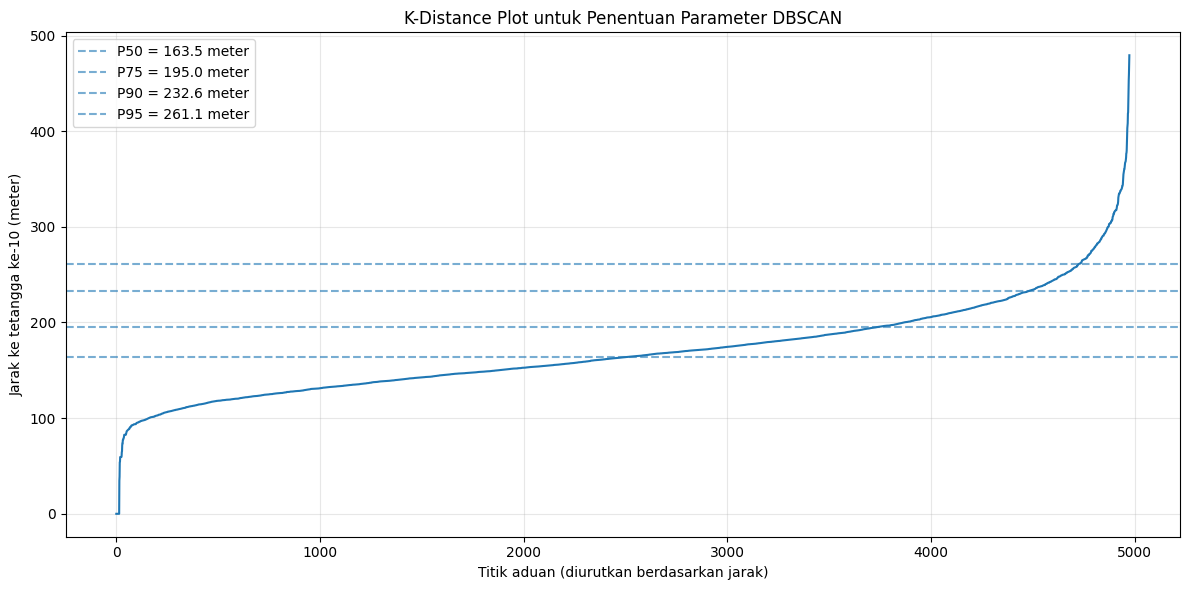

In [137]:
# K-DISTANCE PLOT UNTUK MENENTUKAN AMBANG DBSCAN

import numpy as np
import matplotlib.pyplot as plt

# Urutkan jarak tetangga ke-10 dari yang terkecil
jarak_urut = np.sort(jarak_meter)

# Buat grafik
plt.figure(figsize=(12, 6))

plt.plot(
    np.arange(1, len(jarak_urut) + 1),
    jarak_urut,
    linewidth=1.5
)

# Garis referensi persentil
for p in [50, 75, 90, 95]:
    nilai = np.percentile(jarak_urut, p)
    plt.axhline(
        nilai,
        linestyle="--",
        alpha=0.6,
        label=f"P{p} = {nilai:.1f} meter"
    )

plt.xlabel("Titik aduan (diurutkan berdasarkan jarak)")
plt.ylabel("Jarak ke tetangga ke-10 (meter)")
plt.title("K-Distance Plot untuk Penentuan Parameter DBSCAN")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [138]:
# UJI SENSITIVITAS PARAMETER DBSCAN

import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN

# Gunakan koordinat valid yang sudah disiapkan sebelumnya
koordinat_rad = np.radians(
    data_cluster[["lat", "lon"]].to_numpy()
)

# Kandidat ambang jarak dalam meter
daftar_eps = [225, 250, 275]
min_samples = 10

hasil_uji = []
hasil_label = {}

# Jalankan DBSCAN untuk setiap kandidat
for eps_meter in daftar_eps:

    eps_rad = eps_meter / 6371000

    model = DBSCAN(
        eps=eps_rad,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree"
    )

    label = model.fit_predict(koordinat_rad)
    hasil_label[eps_meter] = label

    jumlah_gerombol = len(set(label)) - (1 if -1 in label else 0)
    jumlah_noise = np.sum(label == -1)
    jumlah_terkelompok = np.sum(label != -1)

    hasil_uji.append({
        "eps_meter": eps_meter,
        "min_samples": min_samples,
        "jumlah_gerombol": jumlah_gerombol,
        "aduan_terkelompok": jumlah_terkelompok,
        "persen_terkelompok": round(
            jumlah_terkelompok / len(label) * 100, 2
        ),
        "jumlah_noise": jumlah_noise,
        "persen_noise": round(
            jumlah_noise / len(label) * 100, 2
        )
    })

# Tampilkan perbandingan
tabel_uji_dbscan = pd.DataFrame(hasil_uji)

print("PERBANDINGAN HASIL DBSCAN")
print("=" * 65)
display(tabel_uji_dbscan)

PERBANDINGAN HASIL DBSCAN


,eps_meter,min_samples,jumlah_gerombol,aduan_terkelompok,persen_terkelompok,jumlah_noise,persen_noise
0,225,10,8,4819,96.90,154,3.10
1,250,10,4,4895,98.43,78,1.57
2,275,10,5,4938,99.30,35,0.70


HASIL PENGELOMPOKAN GEOGRAFIS
Metode       : DBSCAN
Eps          : 250 meter
Min Samples  : 10
Jumlah gerombol: 4


,cluster,jumlah_aduan,status
0,-1,78,Noise
1,0,4861,Gerombol
2,1,10,Gerombol
3,2,11,Gerombol
4,3,13,Gerombol


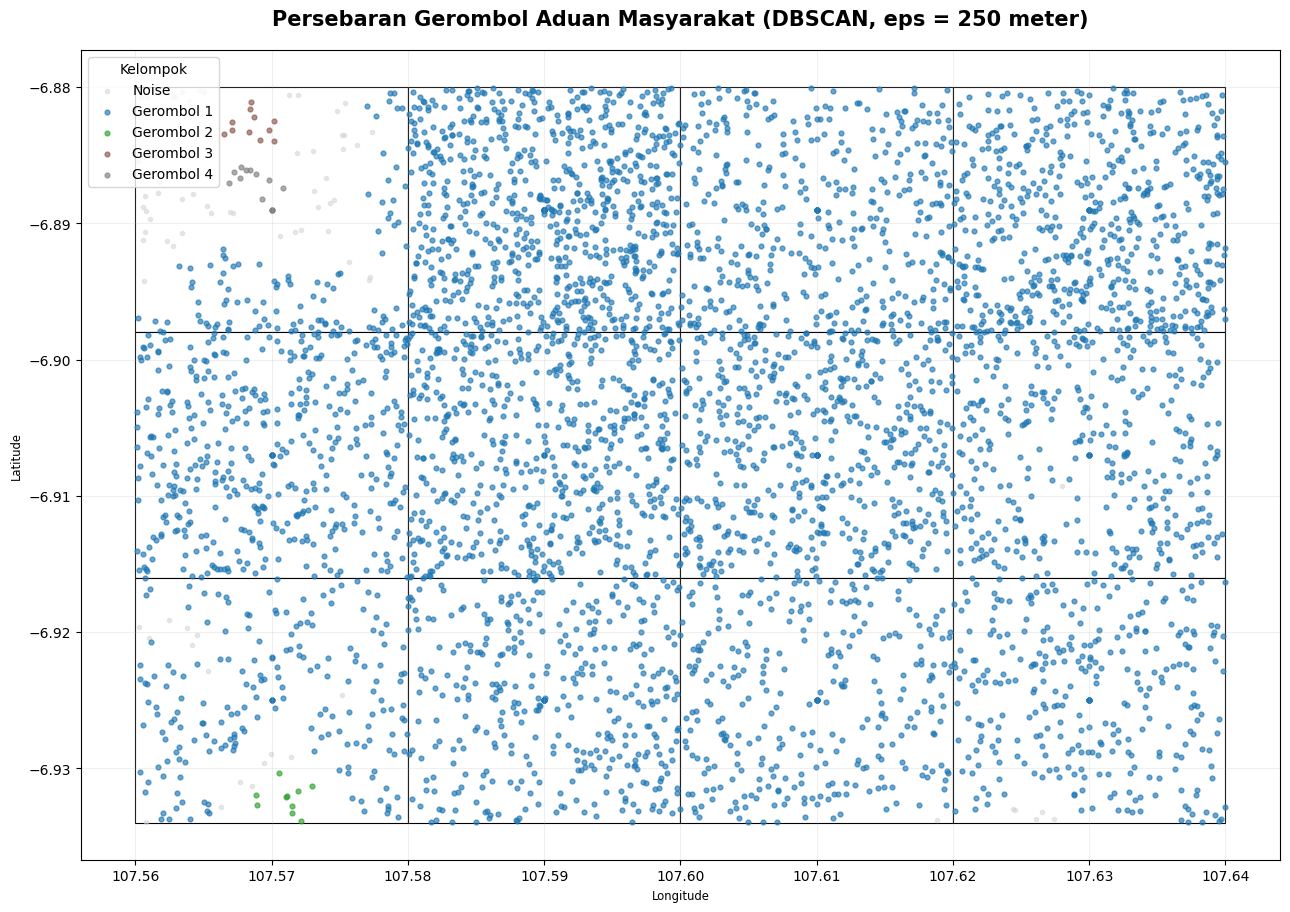

Peta gerombol berhasil disimpan.


In [139]:
# VISUALISASI GEROMBOL GEOGRAFIS DENGAN DBSCAN

import os
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

# 1. Tetapkan parameter kandidat
eps_terpilih = 250
min_samples = 10

# 2. Ambil hasil klasifikasi DBSCAN
data_cluster_final = data_cluster.copy()

data_cluster_final["cluster"] = hasil_label[eps_terpilih]

# 3. Hitung jumlah anggota setiap gerombol
rekap_cluster = (
    data_cluster_final
    .groupby("cluster")
    .size()
    .reset_index(name="jumlah_aduan")
)

rekap_cluster["status"] = np.where(
    rekap_cluster["cluster"] == -1,
    "Noise",
    "Gerombol"
)

print("HASIL PENGELOMPOKAN GEOGRAFIS")
print("=" * 55)
print("Metode       : DBSCAN")
print("Eps          :", eps_terpilih, "meter")
print("Min Samples  :", min_samples)
print("Jumlah gerombol:",
      data_cluster_final.loc[
          data_cluster_final["cluster"] != -1,
          "cluster"
      ].nunique())

display(rekap_cluster)

# 4. Buat peta
fig, ax = plt.subplots(figsize=(13, 12))

# Batas wilayah kelurahan
peta.plot(
    ax=ax,
    facecolor="white",
    edgecolor="black",
    linewidth=0.8
)

# Warna untuk setiap gerombol
warna = plt.cm.tab10(
    np.linspace(0, 1, max(
        1,
        data_cluster_final["cluster"].nunique()
    ))
)

# Plot setiap gerombol
for cluster_id in sorted(
    data_cluster_final["cluster"].unique()
):
    subset = data_cluster_final[
        data_cluster_final["cluster"] == cluster_id
    ]

    if cluster_id == -1:
        subset.plot(
            ax=ax,
            color="lightgray",
            markersize=9,
            alpha=0.5,
            label="Noise"
        )
    else:
        subset.plot(
            ax=ax,
            color=warna[cluster_id],
            markersize=12,
            alpha=0.65,
            label=f"Gerombol {cluster_id + 1}"
        )

ax.set_title(
    "Persebaran Gerombol Aduan Masyarakat "
    "(DBSCAN, eps = 250 meter)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(title="Kelompok", loc="best")
ax.set_aspect("equal")
ax.grid(alpha=0.2)

plt.tight_layout()

# 5. Simpan hasil
os.makedirs("outputs", exist_ok=True)

plt.savefig(
    "outputs/peta_gerombol_dbscan_250m.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Peta gerombol berhasil disimpan.")

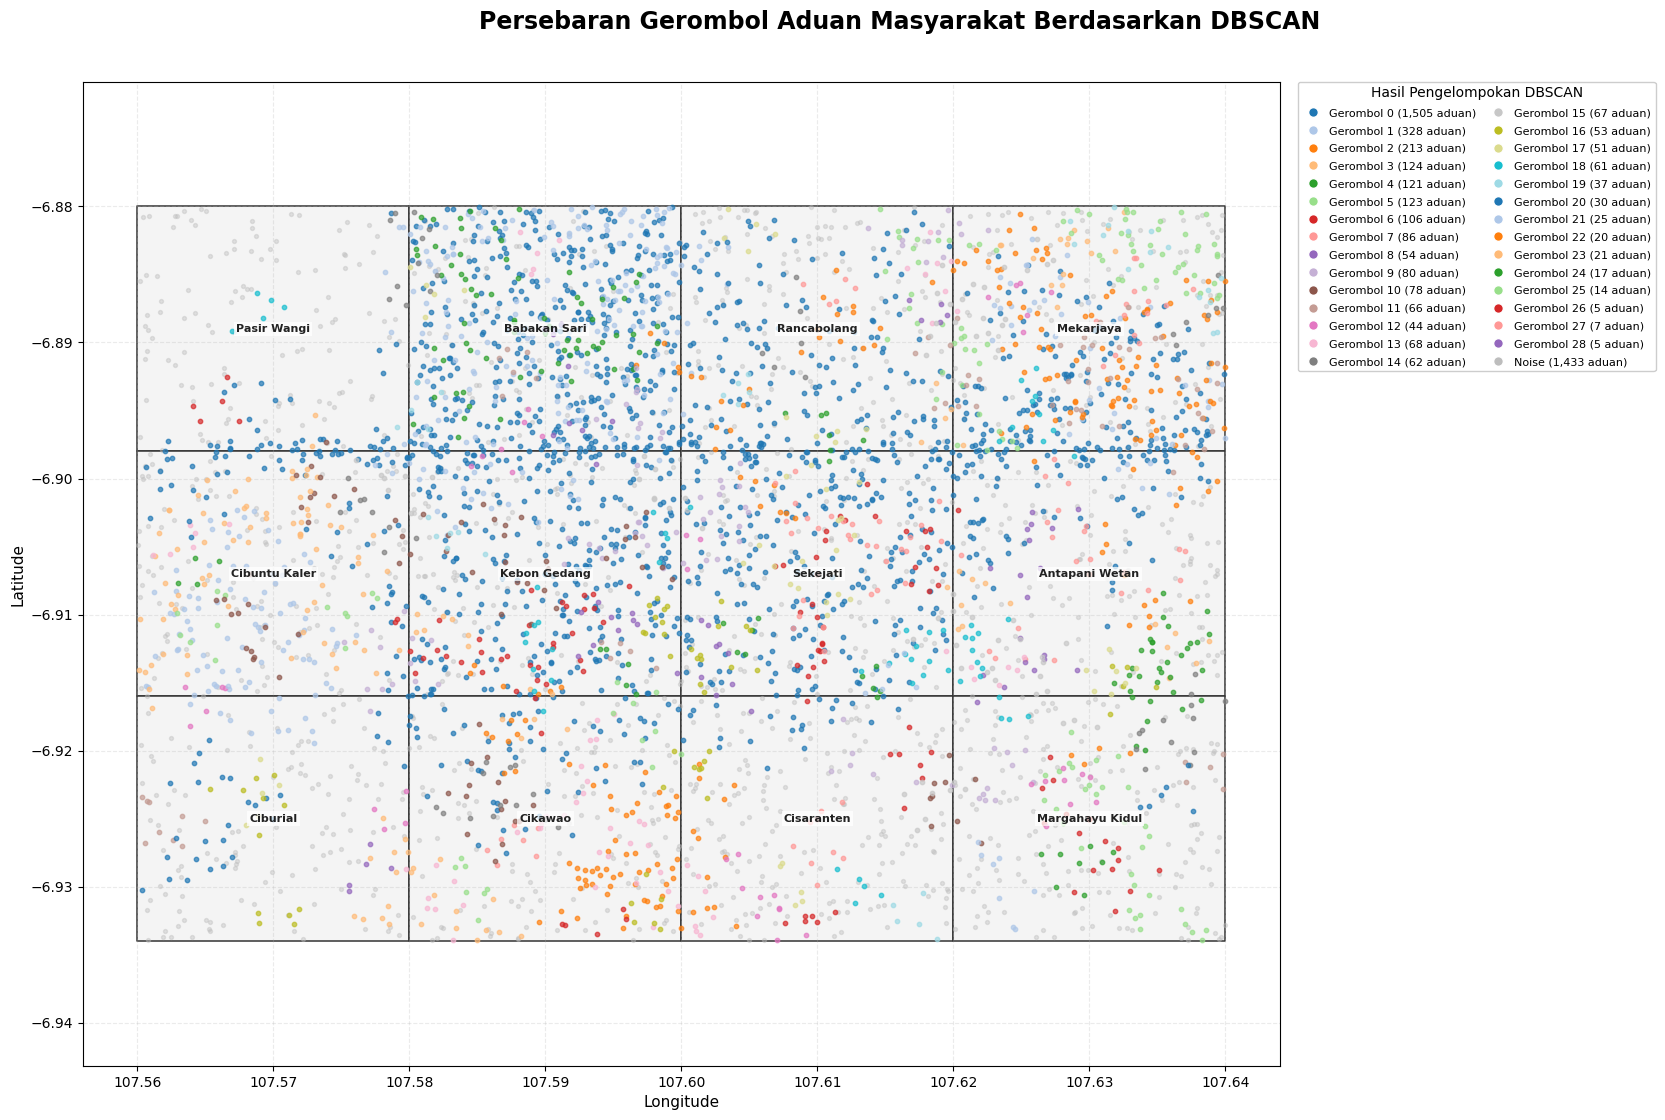

RINGKASAN HASIL DBSCAN
Jumlah titik: 4904
Jumlah gerombol: 29
Gerombol 0: 1,505 aduan
Gerombol 1: 328 aduan
Gerombol 2: 213 aduan
Gerombol 3: 124 aduan
Gerombol 4: 121 aduan
Gerombol 5: 123 aduan
Gerombol 6: 106 aduan
Gerombol 7: 86 aduan
Gerombol 8: 54 aduan
Gerombol 9: 80 aduan
Gerombol 10: 78 aduan
Gerombol 11: 66 aduan
Gerombol 12: 44 aduan
Gerombol 13: 68 aduan
Gerombol 14: 62 aduan
Gerombol 15: 67 aduan
Gerombol 16: 53 aduan
Gerombol 17: 51 aduan
Gerombol 18: 61 aduan
Gerombol 19: 37 aduan
Gerombol 20: 30 aduan
Gerombol 21: 25 aduan
Gerombol 22: 20 aduan
Gerombol 23: 21 aduan
Gerombol 24: 17 aduan
Gerombol 25: 14 aduan
Gerombol 26: 5 aduan
Gerombol 27: 7 aduan
Gerombol 28: 5 aduan
Noise: 1433

Peta berhasil disimpan.


In [140]:

# ============================================================
# VISUALISASI SPASIAL GEROMBOL ADUAN MASYARAKAT (DBSCAN)
# Legenda dipindahkan ke luar area peta
# ============================================================

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# 1. Persiapan data
peta_plot = peta.copy()
titik_plot = df_hasil_cluster.copy()

if not isinstance(peta_plot, gpd.GeoDataFrame):
    peta_plot = gpd.GeoDataFrame(peta_plot, geometry="geometry")

if not isinstance(titik_plot, gpd.GeoDataFrame):
    titik_plot = gpd.GeoDataFrame(titik_plot, geometry="geometry")

if peta_plot.crs is None or titik_plot.crs is None:
    raise ValueError("CRS belum tersedia pada salah satu data.")

titik_plot = titik_plot.to_crs(peta_plot.crs)

# Membersihkan geometri
peta_plot = peta_plot[
    peta_plot.geometry.notna() &
    ~peta_plot.geometry.is_empty
].copy()

titik_plot = titik_plot[
    titik_plot.geometry.notna() &
    ~titik_plot.geometry.is_empty
].copy()

titik_plot["cluster_id"] = pd.to_numeric(
    titik_plot["cluster_id"], errors="coerce"
)
titik_plot = titik_plot.dropna(subset=["cluster_id"]).copy()
titik_plot["cluster_id"] = titik_plot["cluster_id"].astype(int)

# 2. Rekap anggota gerombol
rekap = titik_plot.groupby("cluster_id").size()

cluster_ids = sorted(
    [int(x) for x in rekap.index if x != -1]
)
jumlah_noise = int(rekap.get(-1, 0))

# 3. Warna gerombol
cmap = plt.get_cmap("tab20")

warna_cluster = {
    cid: cmap(i % 20)
    for i, cid in enumerate(cluster_ids)
}

warna_noise = "#BDBDBD"

# 4. Membuat kanvas peta
fig, ax = plt.subplots(figsize=(19, 12))

# Batas dan warna dasar kelurahan
peta_plot.plot(
    ax=ax,
    color="#F4F4F4",
    edgecolor="#333333",
    linewidth=1.1,
    zorder=1
)

# 5. Menampilkan titik noise
if jumlah_noise > 0:
    noise = titik_plot[titik_plot["cluster_id"] == -1]

    noise.plot(
        ax=ax,
        color=warna_noise,
        markersize=8,
        alpha=0.40,
        zorder=2
    )

# 6. Menampilkan setiap gerombol
for cid in cluster_ids:
    subset = titik_plot[titik_plot["cluster_id"] == cid]

    subset.plot(
        ax=ax,
        color=warna_cluster[cid],
        markersize=10,
        alpha=0.70,
        zorder=3
    )

# 7. Label nama kelurahan
if "kelurahan" in peta_plot.columns:
    for _, row in peta_plot.iterrows():
        if pd.notna(row["kelurahan"]):
            titik_label = row.geometry.representative_point()

            ax.annotate(
                str(row["kelurahan"]).title(),
                xy=(titik_label.x, titik_label.y),
                fontsize=8,
                fontweight="bold",
                ha="center",
                va="center",
                color="#222222",
                zorder=4,
                bbox=dict(
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.75,
                    pad=1.5
                )
            )

# 8. Legenda di luar peta
elemen_legend = []

for cid in cluster_ids:
    elemen_legend.append(
        Line2D(
            [0], [0],
            marker="o",
            color="w",
            markerfacecolor=warna_cluster[cid],
            markersize=7,
            label=f"Gerombol {cid} ({int(rekap[cid]):,} aduan)"
        )
    )

if jumlah_noise > 0:
    elemen_legend.append(
        Line2D(
            [0], [0],
            marker="o",
            color="w",
            markerfacecolor=warna_noise,
            markersize=7,
            label=f"Noise ({jumlah_noise:,} aduan)"
        )
    )

# Sisakan ruang di sisi kanan untuk legenda
fig.subplots_adjust(
    left=0.07,
    right=0.70,
    top=0.91,
    bottom=0.09
)

ax.legend(
    handles=elemen_legend,
    title="Hasil Pengelompokan DBSCAN",
    loc="upper left",
    bbox_to_anchor=(1.015, 1.0),
    ncol=2,
    fontsize=8,
    title_fontsize=10,
    frameon=True,
    framealpha=0.98,
    columnspacing=1.0,
    handletextpad=0.4,
    labelspacing=0.7,
    borderaxespad=0
)

# 9. Judul dan tampilan
fig.suptitle(
    "Persebaran Gerombol Aduan Masyarakat Berdasarkan DBSCAN",
    fontsize=17,
    fontweight="bold",
    y=0.97
)

ax.set_xlabel("Longitude", fontsize=11)
ax.set_ylabel("Latitude", fontsize=11)
ax.grid(True, linestyle="--", alpha=0.25)
ax.set_aspect("equal", adjustable="datalim")

# 10. Simpan hasil
os.makedirs("outputs", exist_ok=True)

plt.savefig(
    "outputs/peta_gerombol_dbscan_final.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 11. Ringkasan
print("=" * 60)
print("RINGKASAN HASIL DBSCAN")
print("=" * 60)
print("Jumlah titik:", len(titik_plot))
print("Jumlah gerombol:", len(cluster_ids))

for cid in cluster_ids:
    print(f"Gerombol {cid}: {int(rekap[cid]):,} aduan")

print("Noise:", jumlah_noise)
print("\nPeta berhasil disimpan.")


In [141]:

# ============================================================
# B.1 - CELL 1
# PERBANDINGAN ALTERNATIF KELAS INTENSITAS ADUAN
# ============================================================

import pandas as pd
import numpy as np

# Pastikan hasil perhitungan intensitas tersedia
if "rekap_b1" not in globals():
    raise NameError("Jalankan terlebih dahulu cell perhitungan intensitas B.1.")

data_kelas = rekap_b1.copy()

nilai = data_kelas["intensitas_aduan"].dropna()

print("=" * 70)
print("DISTRIBUSI INTENSITAS ADUAN PER 1.000 PENDUDUK")
print("=" * 70)

print("Jumlah kelurahan :", len(nilai))
print("Minimum          :", round(nilai.min(), 2))
print("Maksimum         :", round(nilai.max(), 2))
print("Rata-rata        :", round(nilai.mean(), 2))
print("Median           :", round(nilai.median(), 2))
print("Standar deviasi  :", round(nilai.std(), 2))

# ------------------------------------------------------------
# Membandingkan 4 dan 5 kelas
# ------------------------------------------------------------

hasil_perbandingan = []

for jumlah_kelas in [4, 5]:

    # Metode Equal Interval
    batas_equal = np.linspace(
        nilai.min(),
        nilai.max(),
        jumlah_kelas + 1
    )

    kelas_equal = pd.cut(
        nilai,
        bins=batas_equal,
        include_lowest=True
    )

    for interval, jumlah in kelas_equal.value_counts(
        sort=False
    ).items():

        hasil_perbandingan.append({
            "Metode": "Equal Interval",
            "Jumlah Kelas": jumlah_kelas,
            "Rentang Kelas": str(interval),
            "Jumlah Kelurahan": jumlah
        })

    # Metode Quantile
    kelas_quantile = pd.qcut(
        nilai,
        q=jumlah_kelas,
        duplicates="drop"
    )

    for interval, jumlah in kelas_quantile.value_counts(
        sort=False
    ).items():

        hasil_perbandingan.append({
            "Metode": "Quantile",
            "Jumlah Kelas": jumlah_kelas,
            "Rentang Kelas": str(interval),
            "Jumlah Kelurahan": jumlah
        })

# ------------------------------------------------------------
# Menampilkan hasil perbandingan
# ------------------------------------------------------------

tabel_perbandingan = pd.DataFrame(hasil_perbandingan)

display(
    tabel_perbandingan.style.format({
        "Jumlah Kelurahan": "{:.0f}"
    })
)

print("\nCATATAN:")
print("- Equal Interval membagi rentang nilai menjadi interval sama lebar.")
print("- Quantile membagi data berdasarkan peringkat/distribusi nilai.")
print("- Perhatikan apakah jumlah kelas aktual Quantile berkurang")
print("  akibat nilai batas yang sama (duplicates).")


DISTRIBUSI INTENSITAS ADUAN PER 1.000 PENDUDUK
Jumlah kelurahan : 12
Minimum          : 3.76
Maksimum         : 32.35
Rata-rata        : 13.49
Median           : 13.03
Standar deviasi  : 6.63


,Metode,Jumlah Kelas,Rentang Kelas,Jumlah Kelurahan
0,Equal Interval,4,"(3.761, 10.909]",2
1,Equal Interval,4,"(10.909, 18.056]",9
2,Equal Interval,4,"(18.056, 25.203]",0
3,Equal Interval,4,"(25.203, 32.35]",1
4,Quantile,4,"(3.761, 11.831]",3
5,Quantile,4,"(11.831, 13.032]",3
6,Quantile,4,"(13.032, 13.852]",3
7,Quantile,4,"(13.852, 32.35]",3
8,Equal Interval,5,"(3.761, 9.48]",2
9,Equal Interval,5,"(9.48, 15.197]",9



CATATAN:
- Equal Interval membagi rentang nilai menjadi interval sama lebar.
- Quantile membagi data berdasarkan peringkat/distribusi nilai.
- Perhatikan apakah jumlah kelas aktual Quantile berkurang
  akibat nilai batas yang sama (duplicates).


In [142]:

# ============================================================
# B.1 - CELL 2
# PEMERIKSAAN NILAI INTENSITAS DAN KANDIDAT KELAS
# ============================================================

import pandas as pd
import numpy as np

data_evaluasi = rekap_b1.copy()

# Urutkan berdasarkan intensitas aduan
data_evaluasi = data_evaluasi.sort_values(
    "intensitas_aduan",
    ascending=True
).reset_index(drop=True)

# Kandidat kelas Quantile 4 dan 5
data_evaluasi["Kelas_Quantile_4"] = pd.qcut(
    data_evaluasi["intensitas_aduan"],
    q=4,
    labels=["Kelas 1", "Kelas 2", "Kelas 3", "Kelas 4"]
)

data_evaluasi["Kelas_Quantile_5"] = pd.qcut(
    data_evaluasi["intensitas_aduan"],
    q=5,
    labels=["Kelas 1", "Kelas 2", "Kelas 3",
            "Kelas 4", "Kelas 5"]
)

# Kandidat kelas Equal Interval 4
batas_equal4 = np.linspace(
    data_evaluasi["intensitas_aduan"].min(),
    data_evaluasi["intensitas_aduan"].max(),
    5
)

data_evaluasi["Kelas_Equal_4"] = pd.cut(
    data_evaluasi["intensitas_aduan"],
    bins=batas_equal4,
    labels=["Kelas 1", "Kelas 2", "Kelas 3", "Kelas 4"],
    include_lowest=True
)

# Tampilkan perbandingan
kolom_tampil = [
    "kelurahan",
    "intensitas_aduan",
    "Kelas_Quantile_4",
    "Kelas_Quantile_5",
    "Kelas_Equal_4"
]

display(
    data_evaluasi[kolom_tampil].round(2)
)

print("\nBATAS KELAS QUANTILE 4:")
print(
    pd.qcut(
        data_evaluasi["intensitas_aduan"],
        q=4
    ).cat.categories
)

print("\nBATAS KELAS QUANTILE 5:")
print(
    pd.qcut(
        data_evaluasi["intensitas_aduan"],
        q=5
    ).cat.categories
)


,kelurahan,intensitas_aduan,Kelas_Quantile_4,Kelas_Quantile_5,Kelas_Equal_4
0,Pasir Wangi,3.76,Kelas 1,Kelas 1,Kelas 1
1,Rancabolang,8.71,Kelas 1,Kelas 1,Kelas 1
2,Mekarjaya,10.98,Kelas 1,Kelas 1,Kelas 2
3,Babakan Sari,12.12,Kelas 2,Kelas 2,Kelas 2
4,Antapani Wetan,12.48,Kelas 2,Kelas 2,Kelas 2
5,Margahayu Kidul,12.66,Kelas 2,Kelas 3,Kelas 2
6,Cibuntu Kaler,13.40,Kelas 3,Kelas 3,Kelas 2
7,Cikawao,13.45,Kelas 3,Kelas 4,Kelas 2
8,Ciburial,13.85,Kelas 3,Kelas 4,Kelas 2
9,Cisaranten,13.87,Kelas 4,Kelas 5,Kelas 2



BATAS KELAS QUANTILE 4:
IntervalIndex([(3.761, 11.831], (11.831, 13.032], (13.032, 13.852],
               (13.852, 32.35]],
              dtype='interval[float64, right]')

BATAS KELAS QUANTILE 5:
IntervalIndex([ (3.761, 11.206], (11.206, 12.555], (12.555, 13.434],
               (13.434, 13.866],  (13.866, 32.35]],
              dtype='interval[float64, right]')


HASIL KLASIFIKASI INTENSITAS ADUAN
METODE: QUANTILE | 4 KELAS
Sangat Rendah   : 3.761 - 11.831 (3 kelurahan)
Rendah          : 11.831 - 13.032 (3 kelurahan)
Sedang          : 13.032 - 13.852 (3 kelurahan)
Tinggi          : 13.852 - 32.350 (3 kelurahan)


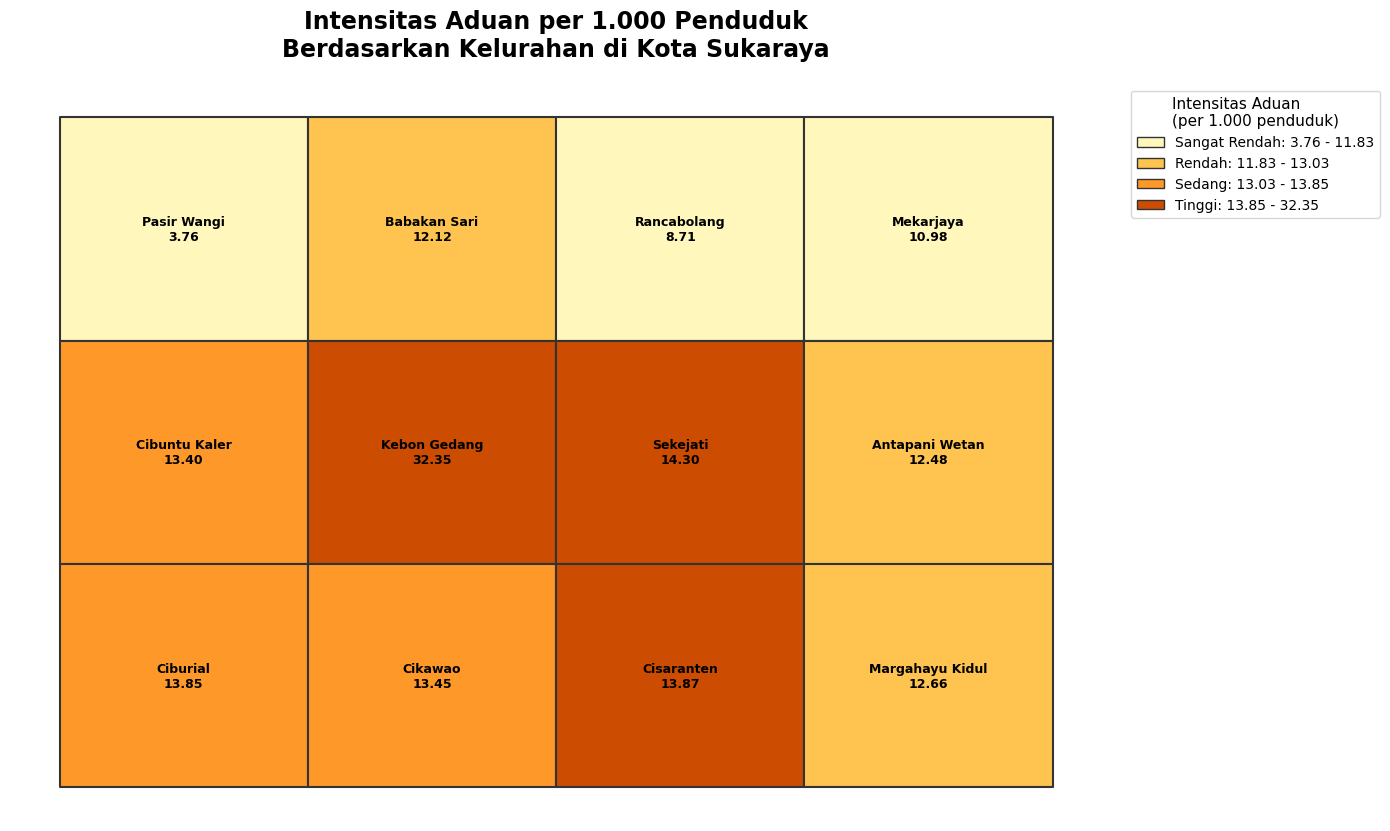


Peta berhasil dibuat.
Lokasi file: outputs/figures/peta_intensitas_aduan_quantile_4_kelas.png


In [143]:

# ============================================================
# B.1 - CELL 3
# PETA KOROPLET INTENSITAS ADUAN PER 1.000 PENDUDUK
# METODE KLASIFIKASI: QUANTILE (4 KELAS)
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ------------------------------------------------------------
# 1. PERSIAPAN DATA
# ------------------------------------------------------------

peta_final = peta_b1.copy()

# Memastikan seluruh nilai intensitas tersedia
if peta_final["intensitas_aduan"].isna().any():
    raise ValueError("Terdapat nilai intensitas kosong.")

# ------------------------------------------------------------
# 2. KLASIFIKASI QUANTILE 4 KELAS
# ------------------------------------------------------------

nama_kelas = [
    "Sangat Rendah",
    "Rendah",
    "Sedang",
    "Tinggi"
]

peta_final["kelas_intensitas"] = pd.qcut(
    peta_final["intensitas_aduan"],
    q=4,
    labels=nama_kelas
)

# Mengambil batas kelas aktual
batas_kelas = pd.qcut(
    peta_final["intensitas_aduan"],
    q=4
).cat.categories

# ------------------------------------------------------------
# 3. MENAMPILKAN DISTRIBUSI KELAS
# ------------------------------------------------------------

print("=" * 65)
print("HASIL KLASIFIKASI INTENSITAS ADUAN")
print("METODE: QUANTILE | 4 KELAS")
print("=" * 65)

for i, interval in enumerate(batas_kelas):
    jumlah = (
        peta_final["kelas_intensitas"]
        == nama_kelas[i]
    ).sum()

    print(
        f"{nama_kelas[i]:15s} : "
        f"{interval.left:.3f} - {interval.right:.3f} "
        f"({jumlah} kelurahan)"
    )

# ------------------------------------------------------------
# 4. MENENTUKAN WARNA BERURUTAN
# ------------------------------------------------------------

warna_kelas = {
    "Sangat Rendah": "#FFF7BC",
    "Rendah": "#FEC44F",
    "Sedang": "#FE9929",
    "Tinggi": "#CC4C02"
}

peta_final["warna"] = (
    peta_final["kelas_intensitas"]
    .astype(str)
    .map(warna_kelas)
)

# ------------------------------------------------------------
# 5. MEMBUAT PETA KOROPLET
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 11))

peta_final.plot(
    color=peta_final["warna"],
    linewidth=1.5,
    edgecolor="#333333",
    ax=ax
)

# Label nama kelurahan dan nilai intensitas
for _, row in peta_final.iterrows():

    titik = row.geometry.representative_point()

    ax.annotate(
        f"{row['kelurahan']}\n"
        f"{row['intensitas_aduan']:.2f}",
        xy=(titik.x, titik.y),
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="black"
    )

# ------------------------------------------------------------
# 6. LEGENDA DENGAN BATAS KELAS DAN SATUAN
# ------------------------------------------------------------

legend_handles = []

for i, kelas in enumerate(nama_kelas):

    interval = batas_kelas[i]

    label = (
        f"{kelas}: "
        f"{interval.left:.2f} - {interval.right:.2f}"
    )

    legend_handles.append(
        mpatches.Patch(
            facecolor=warna_kelas[kelas],
            edgecolor="#333333",
            label=label
        )
    )

ax.legend(
    handles=legend_handles,
    title="Intensitas Aduan\n(per 1.000 penduduk)",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=10,
    title_fontsize=11,
    frameon=True
)

# ------------------------------------------------------------
# 7. JUDUL DAN TATA LETAK
# ------------------------------------------------------------

ax.set_title(
    "Intensitas Aduan per 1.000 Penduduk\n"
    "Berdasarkan Kelurahan di Kota Sukaraya",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_axis_off()
ax.set_aspect("equal")

plt.tight_layout()

# ------------------------------------------------------------
# 8. MENYIMPAN HASIL
# ------------------------------------------------------------

os.makedirs("outputs/figures", exist_ok=True)

file_peta = (
    "outputs/figures/"
    "peta_intensitas_aduan_quantile_4_kelas.png"
)

plt.savefig(
    file_peta,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nPeta berhasil dibuat.")
print("Lokasi file:", file_peta)


In [144]:

# ============================================================
# B.1 - CELL 4
# RINGKASAN HASIL INTENSITAS ADUAN
# ============================================================

# Mengurutkan kelurahan berdasarkan intensitas
ringkasan_intensitas = peta_final[
    ["kelurahan", "intensitas_aduan", "kelas_intensitas"]
].copy()

ringkasan_intensitas = ringkasan_intensitas.sort_values(
    "intensitas_aduan",
    ascending=False
).reset_index(drop=True)

# Menambahkan peringkat
ringkasan_intensitas.insert(
    0,
    "Peringkat",
    range(1, len(ringkasan_intensitas) + 1)
)

# Membulatkan nilai
ringkasan_intensitas["intensitas_aduan"] = (
    ringkasan_intensitas["intensitas_aduan"].round(2)
)

# Menampilkan tabel
print("=" * 75)
print("RINGKASAN INTENSITAS ADUAN PER 1.000 PENDUDUK")
print("=" * 75)

display(ringkasan_intensitas)

# Statistik utama
print("\nKELURAHAN DENGAN INTENSITAS TERTINGGI:")
print(ringkasan_intensitas.iloc[0])

print("\nKELURAHAN DENGAN INTENSITAS TERENDAH:")
print(ringkasan_intensitas.iloc[-1])

# Menyimpan tabel untuk laporan
os.makedirs("outputs/tables", exist_ok=True)

ringkasan_intensitas.to_csv(
    "outputs/tables/ringkasan_intensitas_aduan.csv",
    index=False
)

print("\nTabel berhasil disimpan.")


RINGKASAN INTENSITAS ADUAN PER 1.000 PENDUDUK


,Peringkat,kelurahan,intensitas_aduan,kelas_intensitas
0,1,Kebon Gedang,32.35,Tinggi
1,2,Sekejati,14.30,Tinggi
2,3,Cisaranten,13.87,Tinggi
3,4,Ciburial,13.85,Sedang
4,5,Cikawao,13.45,Sedang
5,6,Cibuntu Kaler,13.40,Sedang
6,7,Margahayu Kidul,12.66,Rendah
7,8,Antapani Wetan,12.48,Rendah
8,9,Babakan Sari,12.12,Rendah
9,10,Mekarjaya,10.98,Sangat Rendah



KELURAHAN DENGAN INTENSITAS TERTINGGI:
Peringkat                      1
kelurahan           Kebon Gedang
intensitas_aduan           32.35
kelas_intensitas          Tinggi
Name: 0, dtype: object

KELURAHAN DENGAN INTENSITAS TERENDAH:
Peringkat                      12
kelurahan             Pasir Wangi
intensitas_aduan             3.76
kelas_intensitas    Sangat Rendah
Name: 11, dtype: object

Tabel berhasil disimpan.


In [146]:

# ============================================================
# B.2 - CELL 6
# VALIDASI HASIL DBSCAN FINAL (EPS = 150 METER)
# ============================================================

import pandas as pd
import numpy as np

# Menggunakan hasil DBSCAN final yang sudah tersedia
hasil_dbscan = df_hasil_cluster_150.copy()

# Memastikan kolom penting tersedia
kolom_wajib = [
    "id_aduan",
    "kelurahan",
    "pokok_masalah_final",
    "cluster_id"
]

for kolom in kolom_wajib:
    if kolom not in hasil_dbscan.columns:
        raise ValueError(f"Kolom {kolom} tidak ditemukan.")

# Memisahkan noise dan anggota cluster
noise_dbscan = hasil_dbscan[
    hasil_dbscan["cluster_id"] == -1
]

anggota_cluster = hasil_dbscan[
    hasil_dbscan["cluster_id"] != -1
]

# Menghitung jumlah cluster unik
jumlah_cluster = anggota_cluster["cluster_id"].nunique()

# Menghitung ukuran setiap cluster
ukuran_cluster = (
    anggota_cluster
    .groupby(["pokok_masalah_final", "cluster_id"])
    .size()
    .reset_index(name="jumlah_anggota")
)

# ============================================================
# RINGKASAN HASIL
# ============================================================

print("=" * 70)
print("VALIDASI HASIL DBSCAN FINAL")
print("Parameter: eps = 150 meter | min_samples = 5")
print("=" * 70)

print(f"Total aduan dianalisis : {len(hasil_dbscan):,}")
print(f"Aduan dalam cluster    : {len(anggota_cluster):,}")
print(f"Aduan noise            : {len(noise_dbscan):,}")
print(f"Jumlah cluster         : {jumlah_cluster:,}")

print(
    f"Persentase anggota cluster : "
    f"{len(anggota_cluster) / len(hasil_dbscan) * 100:.2f}%"
)

print(
    f"Persentase noise           : "
    f"{len(noise_dbscan) / len(hasil_dbscan) * 100:.2f}%"
)

# ============================================================
# DISTRIBUSI UKURAN CLUSTER
# ============================================================

print("\nDISTRIBUSI UKURAN CLUSTER")

print(
    ukuran_cluster["jumlah_anggota"].describe()
)

print("\n10 CLUSTER DENGAN ANGGOTA TERBANYAK")

display(
    ukuran_cluster
    .sort_values("jumlah_anggota", ascending=False)
    .head(10)
)

# ============================================================
# JUMLAH POKOK MASALAH
# ============================================================

print("\nJUMLAH POKOK MASALAH YANG DIANALISIS")

display(
    hasil_dbscan["pokok_masalah_final"]
    .value_counts()
    .rename_axis("pokok_masalah")
    .reset_index(name="jumlah_aduan")
)

# ============================================================
# PEMERIKSAAN DATA LINTAS KELURAHAN
# ============================================================

print("\nDATA HEATMAP")

print("Jumlah baris data_heatmap:", len(data_heatmap))
print(
    "Jumlah cluster lintas kelurahan:",
    data_heatmap["cluster_id"].nunique()
)


VALIDASI HASIL DBSCAN FINAL
Parameter: eps = 150 meter | min_samples = 5
Total aduan dianalisis : 4,904
Aduan dalam cluster    : 676
Aduan noise            : 4,228
Jumlah cluster         : 30
Persentase anggota cluster : 13.78%
Persentase noise           : 86.22%

DISTRIBUSI UKURAN CLUSTER
count    77.000000
mean      8.779221
std       6.610644
min       3.000000
25%       5.000000
50%       6.000000
75%       9.000000
max      33.000000
Name: jumlah_anggota, dtype: float64

10 CLUSTER DENGAN ANGGOTA TERBANYAK


,pokok_masalah_final,cluster_id,jumlah_anggota
12,Jalan Rusak,3,33
10,Jalan Rusak,1,31
17,Jalan Rusak,8,30
18,Jalan Rusak,9,29
21,Jalan Rusak,12,27
29,Jalan Rusak,20,22
22,Jalan Rusak,13,18
20,Jalan Rusak,11,18
25,Jalan Rusak,16,16
14,Jalan Rusak,5,14



JUMLAH POKOK MASALAH YANG DIANALISIS


,pokok_masalah,jumlah_aduan
0,Jalan Rusak,1108
1,Penerangan Jalan,930
2,Sampah,823
3,Drainase dan Banjir,570
4,Ketertiban Umum,511
5,Air Bersih,397
6,Fasilitas Umum,366
7,Lain-lain,199



DATA HEATMAP
Jumlah baris data_heatmap: 298
Jumlah cluster lintas kelurahan: 17


In [147]:

# ============================================================
# B.2 - CELL 7
# IDENTIFIKASI GEROMBOL LINTAS KELURAHAN
# ============================================================

# Menggunakan hasil DBSCAN final
data_analisis = df_hasil_cluster_150.copy()

# Memastikan kolom tersedia
kolom_wajib = [
    "pokok_masalah_final",
    "cluster_id",
    "kelurahan",
    "id_aduan"
]

for kolom in kolom_wajib:
    if kolom not in data_analisis.columns:
        raise ValueError(f"Kolom {kolom} tidak ditemukan.")

# Menghapus noise
data_anggota = data_analisis[
    data_analisis["cluster_id"] != -1
].copy()

# Menghitung karakteristik setiap gerombol
rekap_cluster = (
    data_anggota
    .groupby(
        ["pokok_masalah_final", "cluster_id"]
    )
    .agg(
        jumlah_aduan=("id_aduan", "count"),
        jumlah_kelurahan=("kelurahan", "nunique"),
        daftar_kelurahan=(
            "kelurahan",
            lambda x: ", ".join(sorted(x.dropna().unique()))
        )
    )
    .reset_index()
)

# Mengidentifikasi gerombol lintas kelurahan
cluster_lintas = rekap_cluster[
    rekap_cluster["jumlah_kelurahan"] > 1
].copy()

# Mengurutkan berdasarkan jumlah aduan
cluster_lintas = cluster_lintas.sort_values(
    ["jumlah_aduan", "jumlah_kelurahan"],
    ascending=False
).reset_index(drop=True)

# ============================================================
# RINGKASAN HASIL
# ============================================================

print("=" * 75)
print("HASIL IDENTIFIKASI GEROMBOL LINTAS KELURAHAN")
print("=" * 75)

print("Total gerombol kategori :", len(rekap_cluster))
print("Gerombol lintas kelurahan :", len(cluster_lintas))
print(
    "Aduan dalam gerombol lintas kelurahan :",
    cluster_lintas["jumlah_aduan"].sum()
)

print(
    "Jumlah kategori masalah yang memiliki gerombol lintas wilayah :",
    cluster_lintas["pokok_masalah_final"].nunique()
)

# ============================================================
# TABEL GEROMBOL LINTAS KELURAHAN
# ============================================================

print("\nDAFTAR GEROMBOL LINTAS KELURAHAN")

display(
    cluster_lintas[
        [
            "pokok_masalah_final",
            "cluster_id",
            "jumlah_aduan",
            "jumlah_kelurahan",
            "daftar_kelurahan"
        ]
    ]
)

# ============================================================
# PEMERIKSAAN UKURAN GEROMBOL
# ============================================================

print("\nPEMERIKSAAN UKURAN GEROMBOL DI BAWAH MIN_SAMPLES")

cluster_kecil = rekap_cluster[
    rekap_cluster["jumlah_aduan"] < 5
]

print("Jumlah gerombol berukuran kurang dari 5:",
      len(cluster_kecil))

if len(cluster_kecil) > 0:
    display(cluster_kecil)

# ============================================================
# PERBANDINGAN DENGAN DATA HEATMAP
# ============================================================

print("\nPERBANDINGAN DENGAN DATA HEATMAP SEBELUMNYA")

print("Baris data_heatmap :", len(data_heatmap))
print("Aduan hasil identifikasi:", cluster_lintas["jumlah_aduan"].sum())
print("Gerombol hasil identifikasi:", len(cluster_lintas))



HASIL IDENTIFIKASI GEROMBOL LINTAS KELURAHAN
Total gerombol kategori : 77
Gerombol lintas kelurahan : 20
Aduan dalam gerombol lintas kelurahan : 298
Jumlah kategori masalah yang memiliki gerombol lintas wilayah : 4

DAFTAR GEROMBOL LINTAS KELURAHAN


,pokok_masalah_final,cluster_id,jumlah_aduan,jumlah_kelurahan,daftar_kelurahan
0,Jalan Rusak,3,33,4,"Babakan Sari, Kebon Gedang, Rancabolang, Sekejati"
1,Jalan Rusak,1,31,2,"Babakan Sari, Kebon Gedang"
2,Jalan Rusak,8,30,4,"Antapani Wetan, Mekarjaya, Rancabolang, Sekejati"
3,Jalan Rusak,9,29,2,"Rancabolang, Sekejati"
4,Jalan Rusak,12,27,2,"Antapani Wetan, Mekarjaya"
5,Jalan Rusak,11,18,2,"Cibuntu Kaler, Kebon Gedang"
6,Jalan Rusak,13,18,2,"Rancabolang, Sekejati"
7,Jalan Rusak,16,16,2,"Antapani Wetan, Mekarjaya"
8,Jalan Rusak,5,14,2,"Babakan Sari, Kebon Gedang"
9,Jalan Rusak,18,11,2,"Babakan Sari, Kebon Gedang"



PEMERIKSAAN UKURAN GEROMBOL DI BAWAH MIN_SAMPLES
Jumlah gerombol berukuran kurang dari 5: 1


,pokok_masalah_final,cluster_id,jumlah_aduan,jumlah_kelurahan,daftar_kelurahan
31,Jalan Rusak,22,3,1,Sekejati



PERBANDINGAN DENGAN DATA HEATMAP SEBELUMNYA
Baris data_heatmap : 298
Aduan hasil identifikasi: 298
Gerombol hasil identifikasi: 20


In [148]:

# ============================================================
# B.2 - CELL 8
# VALIDASI LABEL CLUSTER DAN DATA HEATMAP
# ============================================================

# 1. Memeriksa jumlah label cluster pada data_heatmap
print("=" * 75)
print("A. PEMERIKSAAN LABEL CLUSTER DATA HEATMAP")
print("=" * 75)

print("Jumlah baris data_heatmap:", len(data_heatmap))
print("Jumlah label_cluster unik:",
      data_heatmap["label_cluster"].nunique())

print("Jumlah kombinasi kategori + cluster_id:",
      data_heatmap[
          ["pokok_masalah_final", "cluster_id"]
      ].drop_duplicates().shape[0])

# 2. Menghitung ulang cluster berdasarkan data_heatmap
rekap_heatmap = (
    data_heatmap
    .groupby(["pokok_masalah_final", "cluster_id"])
    .agg(
        jumlah_aduan=("id_aduan", "count"),
        jumlah_kelurahan=("kelurahan", "nunique"),
        daftar_kelurahan=(
            "kelurahan",
            lambda x: ", ".join(sorted(x.dropna().unique()))
        ),
        jumlah_label=("label_cluster", "nunique")
    )
    .reset_index()
)

heatmap_lintas = rekap_heatmap[
    rekap_heatmap["jumlah_kelurahan"] > 1
].copy()

print("\nB. HASIL PENGHITUNGAN DATA HEATMAP")
print("Jumlah gerombol lintas:", len(heatmap_lintas))
print("Jumlah aduan lintas:", heatmap_lintas["jumlah_aduan"].sum())

# 3. Memeriksa cluster kecil pada hasil DBSCAN
print("\nC. PEMERIKSAAN CLUSTER KECIL")

cluster_kecil_detail = (
    data_anggota
    .groupby(["pokok_masalah_final", "cluster_id"])
    .agg(
        jumlah_aduan=("id_aduan", "count"),
        kelurahan=("kelurahan", lambda x: ", ".join(sorted(x.unique())))
    )
    .reset_index()
)

display(
    cluster_kecil_detail[
        cluster_kecil_detail["jumlah_aduan"] < 5
    ]
)

# 4. Memeriksa penggunaan ulang cluster_id
print("\nD. PEMERIKSAAN ID CLUSTER YANG DIGUNAKAN ULANG")

id_reuse = (
    data_anggota
    .groupby("cluster_id")
    .agg(
        jumlah_kategori=("pokok_masalah_final", "nunique"),
        kategori=(
            "pokok_masalah_final",
            lambda x: ", ".join(sorted(x.unique()))
        )
    )
    .reset_index()
)

display(
    id_reuse[id_reuse["jumlah_kategori"] > 1]
)

# 5. Memeriksa cluster kecil secara khusus
print("\nE. PEMERIKSAAN CLUSTER ID 22")

display(
    data_anggota[
        data_anggota["cluster_id"] == 22
    ].groupby("pokok_masalah_final")
    .size()
    .reset_index(name="jumlah_aduan")
)

print("\nVALIDASI SELESAI")


A. PEMERIKSAAN LABEL CLUSTER DATA HEATMAP
Jumlah baris data_heatmap: 298
Jumlah label_cluster unik: 20
Jumlah kombinasi kategori + cluster_id: 20

B. HASIL PENGHITUNGAN DATA HEATMAP
Jumlah gerombol lintas: 20
Jumlah aduan lintas: 298

C. PEMERIKSAAN CLUSTER KECIL


,pokok_masalah_final,cluster_id,jumlah_aduan,kelurahan
31,Jalan Rusak,22,3,Sekejati



D. PEMERIKSAAN ID CLUSTER YANG DIGUNAKAN ULANG


,cluster_id,jumlah_kategori,kategori
0,0,7,"Air Bersih, Drainase dan Banjir, Fasilitas Umu..."
1,1,4,"Drainase dan Banjir, Jalan Rusak, Penerangan J..."
2,2,4,"Drainase dan Banjir, Jalan Rusak, Penerangan J..."
3,3,4,"Drainase dan Banjir, Jalan Rusak, Penerangan J..."
4,4,4,"Drainase dan Banjir, Jalan Rusak, Penerangan J..."
5,5,4,"Drainase dan Banjir, Jalan Rusak, Penerangan J..."
6,6,4,"Drainase dan Banjir, Jalan Rusak, Penerangan J..."
7,7,3,"Jalan Rusak, Penerangan Jalan, Sampah"
8,8,3,"Jalan Rusak, Penerangan Jalan, Sampah"
9,9,3,"Jalan Rusak, Penerangan Jalan, Sampah"



E. PEMERIKSAAN CLUSTER ID 22


,pokok_masalah_final,jumlah_aduan
0,Jalan Rusak,3



VALIDASI SELESAI


In [149]:

# ============================================================
# B.2 - CELL 9
# INVESTIGASI CLUSTER KECIL (JALAN RUSAK - CLUSTER 22)
# ============================================================

# Mengambil data cluster 22 khusus kategori Jalan Rusak
cluster_22 = df_hasil_cluster_150[
    (df_hasil_cluster_150["pokok_masalah_final"] == "Jalan Rusak") &
    (df_hasil_cluster_150["cluster_id"] == 22)
].copy()

print("=" * 75)
print("INVESTIGASI JALAN RUSAK - CLUSTER 22")
print("=" * 75)

print("Jumlah baris:", len(cluster_22))
print("Jumlah ID aduan unik:", cluster_22["id_aduan"].nunique())
print("Kelurahan:", cluster_22["kelurahan"].unique())

# Menampilkan seluruh kolom yang relevan
kolom_tampil = [
    kolom for kolom in [
        "id_aduan",
        "pokok_masalah_final",
        "cluster_id",
        "kelurahan",
        "longitude",
        "latitude",
        "lon",
        "lat"
    ]
    if kolom in cluster_22.columns
]

print("\nDETAIL DATA CLUSTER 22")
display(cluster_22[kolom_tampil])

# Membandingkan dengan data_heatmap
print("\nPEMERIKSAAN PADA DATA HEATMAP")

cluster_22_heatmap = data_heatmap[
    (data_heatmap["pokok_masalah_final"] == "Jalan Rusak") &
    (data_heatmap["cluster_id"] == 22)
]

print("Jumlah baris dalam heatmap:", len(cluster_22_heatmap))

# Memeriksa distribusi ukuran cluster Jalan Rusak
print("\nDISTRIBUSI UKURAN CLUSTER JALAN RUSAK")

display(
    df_hasil_cluster_150[
        (df_hasil_cluster_150["pokok_masalah_final"] == "Jalan Rusak") &
        (df_hasil_cluster_150["cluster_id"] != -1)
    ]
    .groupby("cluster_id")
    .agg(
        jumlah_aduan=("id_aduan", "count"),
        jumlah_id_unik=("id_aduan", "nunique"),
        jumlah_kelurahan=("kelurahan", "nunique")
    )
    .sort_values("jumlah_aduan")
    .head(10)
)

print("\nINVESTIGASI SELESAI")


INVESTIGASI JALAN RUSAK - CLUSTER 22
Jumlah baris: 3
Jumlah ID aduan unik: 3
Kelurahan: ['Sekejati']

DETAIL DATA CLUSTER 22


,id_aduan,pokok_masalah_final,cluster_id,kelurahan,lon,lat
1627,ADU-004780,Jalan Rusak,22,Sekejati,107.609010,-6.906451
1822,ADU-002639,Jalan Rusak,22,Sekejati,107.608011,-6.906087
2417,ADU-001811,Jalan Rusak,22,Sekejati,107.608498,-6.906843



PEMERIKSAAN PADA DATA HEATMAP
Jumlah baris dalam heatmap: 0

DISTRIBUSI UKURAN CLUSTER JALAN RUSAK


,jumlah_aduan,jumlah_id_unik,jumlah_kelurahan
cluster_id,,,
22,3,3,1
0,5,5,1
29,5,5,1
2,5,5,2
27,5,5,1
26,5,5,1
28,5,5,1
6,7,7,1
17,7,7,2



INVESTIGASI SELESAI


### VISUALISASI SPASIAL GEROMBOL LINTAS KELURAHAN

RINGKASAN VISUALISASI GEROMBOL LINTAS KELURAHAN
Jumlah gerombol : 20
Jumlah aduan    : 298
Jumlah kategori : 4


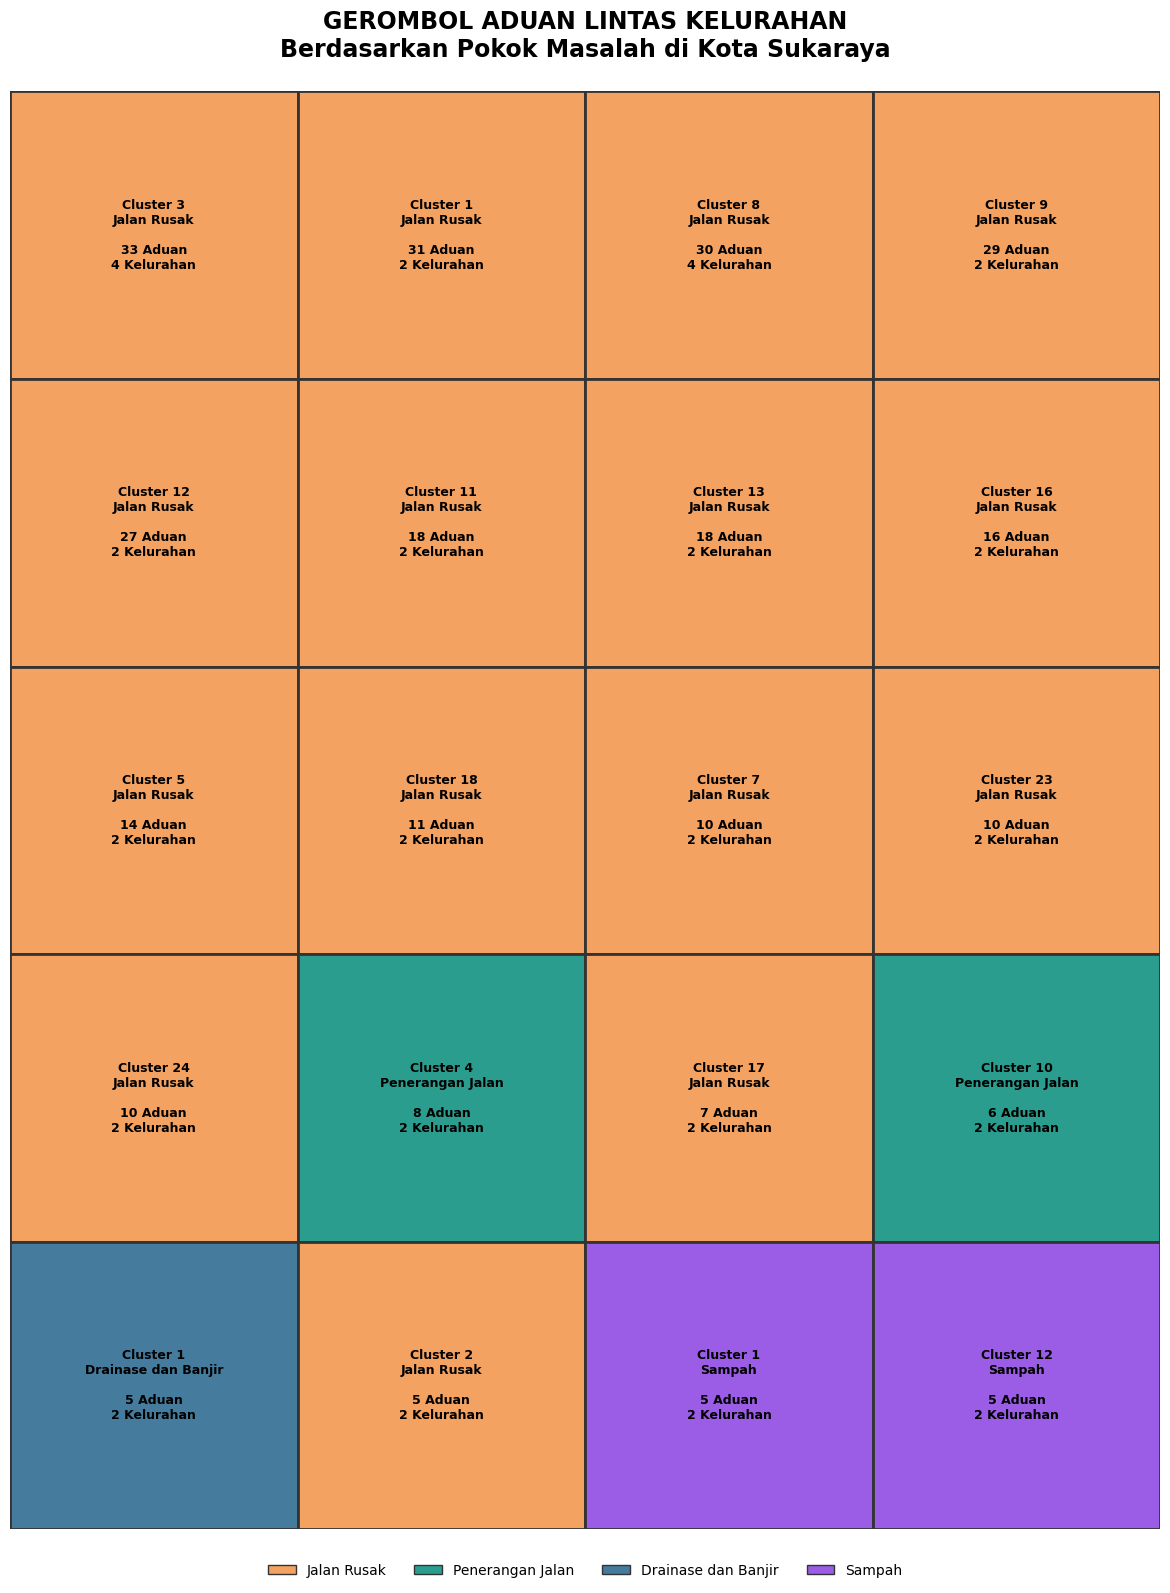

In [154]:

# ============================================================
# B.2 - CELL 13
# VISUALISASI GRID GEROMBOL LINTAS KELURAHAN
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# ------------------------------------------------------------
# 1. PERSIAPAN DATA
# ------------------------------------------------------------

df_visual = cluster_lintas.copy()

df_visual = df_visual.sort_values(
    "jumlah_aduan",
    ascending=False
).reset_index(drop=True)

# Warna berdasarkan kategori masalah
kategori_warna = {
    "Jalan Rusak": "#F4A261",
    "Penerangan Jalan": "#2A9D8F",
    "Drainase dan Banjir": "#457B9D",
    "Sampah": "#9B5DE5"
}

# ------------------------------------------------------------
# 2. PENGATURAN GRID
# ------------------------------------------------------------

jumlah_cluster = len(df_visual)

kolom = 4
baris = int(np.ceil(jumlah_cluster / kolom))

fig, ax = plt.subplots(
    figsize=(16, baris * 3.2)
)

ax.set_xlim(0, kolom)
ax.set_ylim(0, baris)
ax.set_aspect("equal")
ax.axis("off")

# ------------------------------------------------------------
# 3. MEMBUAT KOTAK SETIAP GEROMBOL
# ------------------------------------------------------------

for i, row in df_visual.iterrows():

    x = i % kolom
    y = baris - 1 - (i // kolom)

    kategori = row["pokok_masalah_final"]
    cluster_id = row["cluster_id"]
    jumlah = row["jumlah_aduan"]
    jumlah_kel = row["jumlah_kelurahan"]

    warna = kategori_warna.get(
        kategori,
        "#BDBDBD"
    )

    # Kotak gerombol
    kotak = patches.Rectangle(
        (x, y),
        1,
        1,
        facecolor=warna,
        edgecolor="#333333",
        linewidth=2
    )

    ax.add_patch(kotak)

    # Informasi di dalam kotak
    teks = (
        f"Cluster {cluster_id}\n"
        f"{kategori}\n\n"
        f"{jumlah} Aduan\n"
        f"{jumlah_kel} Kelurahan"
    )

    ax.text(
        x + 0.5,
        y + 0.5,
        teks,
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="black",
        wrap=True
    )

# ------------------------------------------------------------
# 4. JUDUL VISUALISASI
# ------------------------------------------------------------

ax.set_title(
    "GEROMBOL ADUAN LINTAS KELURAHAN\n"
    "Berdasarkan Pokok Masalah di Kota Sukaraya",
    fontsize=17,
    fontweight="bold",
    pad=25
)

# ------------------------------------------------------------
# 5. LEGENDA KATEGORI
# ------------------------------------------------------------

legend_items = [
    patches.Patch(
        facecolor=warna,
        edgecolor="#333333",
        label=kategori
    )
    for kategori, warna in kategori_warna.items()
    if kategori in df_visual["pokok_masalah_final"].values
]

ax.legend(
    handles=legend_items,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.015),
    ncol=4,
    frameon=False,
    fontsize=10
)

plt.tight_layout()

# ------------------------------------------------------------
# 6. RINGKASAN
# ------------------------------------------------------------

print("=" * 65)
print("RINGKASAN VISUALISASI GEROMBOL LINTAS KELURAHAN")
print("=" * 65)

print("Jumlah gerombol :", jumlah_cluster)
print("Jumlah aduan    :", df_visual["jumlah_aduan"].sum())
print(
    "Jumlah kategori :",
    df_visual["pokok_masalah_final"].nunique()
)

plt.savefig(
    "Visualisasi_Grid_Gerombol.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
